In [23]:
# [셀 1: 🛠️ 글로벌 설정 (수정됨)]

import os
import json
import glob
import sys
import pandas as pd 
from datetime import datetime

# --- 1. RDKit 및 필수 라이브러리 임포트 ---
try:
    from rdkit import Chem
    from rdkit.Chem import AllChem, Descriptors, Lipinski, QED
    from rdkit import RDConfig
    from rdkit.Chem import FilterCatalog 
    
    sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
    try:
        import sascorer
    except ImportError:
        print("⚠️ [경고] SA_Score 모듈 로드 실패. 점수는 5.0으로 처리됩니다.")
        sascorer = None

    print("✅ RDKit 모듈 로드 완료.")
except ImportError:
    print("❌ [오류] RDKit 모듈을 찾을 수 없습니다.")

# --- 2. 이전 단계(Notebook 1) 설정 불러오기 ---
try:
    # 현재 위치 기준, 가장 최근 결과 폴더 찾기
    recent_dirs = sorted(glob.glob("./pipeline_results_*"), key=os.path.getmtime)
    if not recent_dirs:
        raise FileNotFoundError("이전 단계 결과 폴더(./pipeline_results_*)를 찾을 수 없습니다.")
    
    last_results_dir = recent_dirs[-1]
    config_path = os.path.join(last_results_dir, "pipeline_output_config.json")
    
    if not os.path.exists(config_path):
        raise FileNotFoundError(f"설정 파일이 없습니다: {config_path}")
        
    print(f"📂 설정 파일 로드 중: {config_path}")
    with open(config_path, 'r') as f:
        PREV_CONFIG = json.load(f)
        
    # --- 설정 덮어쓰기 ---
    DRUGAI_DIR = PREV_CONFIG["DRUGAI_DIR"]
    GENERATION_TARGET = PREV_CONFIG["GENERATION_TARGET"]
    RECEPTORS_CONFIG = PREV_CONFIG["RECEPTORS_CONFIG"]
    
    # 입력 파일 경로 설정
    best_candidates_path = os.path.join(last_results_dir, "BEST_CANDIDATES_FOR_EVOLUTION.csv")
    if os.path.exists(best_candidates_path):
        INPUT_HITS_PATH = best_candidates_path
        print(f"   ★ [자동 감지] 선별된 최적 후보 파일이 발견되었습니다!")
    else:
        INPUT_HITS_PATH = PREV_CONFIG["FINAL_CSV_PATH"]
        print(f"   ⚠️ [주의] 최적 후보 파일이 없어 전체 결과 파일을 사용합니다.")

    if os.path.exists(INPUT_HITS_PATH):
        _df_check = pd.read_csv(INPUT_HITS_PATH)
        print(f"   > 입력 데이터: {_df_check.shape[0]}개 로드 예정")

except Exception as e:
    print(f"⚠️ [주의] 자동 설정 로드 실패: {e}")

# --- 3. 환경 및 모델 경로 (고정값) ---
POCKET2MOL_ENV_NAME = "Pocket2Mol"
POCKET2MOL_DIR = "/home/nudge/Pocket2Mol"
GNINA_ENV_NAME = "gnina"
POCKET2MOL_CONFIG = "/home/nudge/Pocket2Mol/configs/sample_for_pdb.yml"
GNINA_EXECUTABLE_PATH = "/home/nudge/gnina_binary"

# [★수정됨] Affinity 모델 경로 및 앙상블 리스트 정의
AFFINITY_CKPT_DIR = "/home/nudge/Project/drugai/checkpoints"
AFFINITY_ENSEMBLE_MODELS = [
    "egnn_seed41.pt", 
    "egnn_seed42.pt", 
    "egnn_seed43.pt"
]

# ADMET 모델 경로
ADMET_MODEL_CKPT_DIR = "/home/nudge/Project/drugai/models"

# --- 4. 대조군 정보 (고정값) ---
CONTROL_LIGANDS_SMILES = [{"id": "LIG_Aspirin", "SMILES": "CC(=O)Oc1ccccc1C(=O)O"}]
CONTROL_LIGANDS_PDB = [
    {"id": "LIG_T44", "path": "/home/nudge/Project/drugai/data/PDB/input/ligand/TT4.pdb"},
    {"id": "LIG_Tafamidis", "path": "/home/nudge/Project/drugai/data/PDB/input/ligand/tifamidis.pdb"}
]
TAFAMIDIS_SMILES = "O=C(O)c1ccc2nc(oc2c1)c1cc(cc(c1)Cl)Cl"

# --- 5. 기타 설정 ---
DEVICE = "cuda:0"
NUM_GENERATIONS_PER_CYCLE = 2000 

print("\n✅ [셀 1] 2단계 글로벌 설정 완료. (앙상블 모델 적용됨)")

✅ RDKit 모듈 로드 완료.
📂 설정 파일 로드 중: ./pipeline_results_20251122_140342/pipeline_output_config.json
   ★ [자동 감지] 선별된 최적 후보 파일이 발견되었습니다!
   > 입력 데이터: 5개 로드 예정

✅ [셀 1] 2단계 글로벌 설정 완료. (앙상블 모델 적용됨)


In [27]:
## [셀 2: ⚖️ 필터링 "규칙 엔진" 정의]
#
# 파이프라인의 모든 필터링 임계값을 이곳에서 관리합니다.
#

print("--- [셀 2] 필터링 규칙 엔진 설정 ---")

# --- (1) 최종 목표 후보 수 ---
TARGET_HIT_COUNT = 5
print(f"  > 목표 최종 후보 수: {TARGET_HIT_COUNT} 개")

# --- (2) 1차: 물리화학적 (RDKit) 필터 ---
MW_MIN = 250
MW_MAX = 500
LOGP_MIN = 2.0
LOGP_MAX = 5.0
HBD_MAX = 5    # ◀ [수정] 3 -> 5 (Lipinski 표준)
HBA_MAX = 10   # ◀ [수정] 7 -> 10 (Lipinski 표준)
TPSA_MIN = 40
TPSA_MAX = 140 # ◀ [수정] 120 -> 140 (Veber 룰 표준 상한선)
ROTB_MAX = 10
SA_SCORE_MAX = 6.0
PAINS_ALERTS_MAX = 0 
QED_MIN = 0.6

# --- (3) 2차: ADMET (ML) 필터 ---
HERG_PROB_MAX = 0.5
AQSOL_PRED_MIN = -5.0
CYP3A4_FLAG_PASS = 0 # (0 = Pass, 1 = Fail로 가정)

# --- (4) 3차: Binding Affinity (ML) 필터 ---
# (Tafamidis의 ML 점수(약 5.0)를 기준으로 설정)
ML_AFFINITY_POTENCY_THRESH = 6.0
print(f"  > 3차 ML 필터 기준: pKd_ML_MT_V30M > {ML_AFFINITY_POTENCY_THRESH}")

# --- (5) 4차: 최종 Gnina 필터 (동적 기준) ---
# [셀 4]에서 대조군(Tafamidis)을 Gnina로 실행한 후 이 변수에 값이 할당됩니다.
G_POTENCY_THRESH = None 
G_SELECTIVITY_MODE = "MT_GT_WT" # (MT > WT) 

print("✅ [셀 2] 규칙 엔진 변수 로드 완료.")

--- [셀 2] 필터링 규칙 엔진 설정 ---
  > 목표 최종 후보 수: 5 개
  > 3차 ML 필터 기준: pKd_ML_MT_V30M > 6.0
✅ [셀 2] 규칙 엔진 변수 로드 완료.


In [28]:
# [셀 3: 📦 헬퍼 함수 정의 (통합 업데이트 완료)]
# 업데이트 사항:
# 1. prepare_receptors_for_gnina 함수 추가 (누락 해결)
# 2. calculate_rdkit_properties 함수 강화 (QED, SA, Tanimoto 계산 추가)
# 3. Gnina 도킹 시 TQDM 진행률 바 적용

import os
import glob
import pandas as pd
import subprocess
import numpy as np
import sys
import re
from rdkit import Chem, DataStructs, RDConfig
from rdkit.Chem import AllChem, Descriptors, Lipinski, QED, FilterCatalog
from joblib import Parallel, delayed
from tqdm.auto import tqdm

# --- SA Score 모듈 로드 ---
sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
try:
    import sascorer
    print("✅ [Helper] SA_Score 모듈 로드 성공.")
except ImportError:
    sascorer = None
    print("⚠️ [Helper] SA_Score 모듈 없음. (점수 10.0 처리)")

print("--- [셀 3] 헬퍼 함수 정의 (Full Version) ---")

# --- 유틸리티 ---
def run_command(command, error_message):
    try:
        result = subprocess.run(command, shell=True, check=False, capture_output=True, text=True, encoding='utf-8')
        return result
    except Exception as e:
        return None

# --- 1. RDKit 필터 & 물성 계산 (기능 강화됨) ---
def calculate_rdkit_properties(df_input):
    print("  [2] RDKit 물리화학적 속성 및 특허성(Tanimoto) 계산...")
    df = df_input.copy()
    mols = df['SMILES'].apply(Chem.MolFromSmiles)
    mols_valid = mols.notna()
    
    if mols_valid.sum() == 0: return df.assign(pass_rdkit=False)

    # PAINS 필터 준비
    try:
        params = FilterCatalog.FilterCatalogParams()
        params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS)
        pains_catalog = FilterCatalog.FilterCatalog(params)
    except: pains_catalog = None

    # Tafamidis 준비 (유사도 비교용)
    try:
        tafa_smi = "O=C(O)c1ccc2nc(oc2c1)c1cc(cc(c1)Cl)Cl" # TAFAMIDIS_SMILES가 없을 경우 대비
        if 'TAFAMIDIS_SMILES' in globals(): tafa_smi = TAFAMIDIS_SMILES
        tafa_mol = Chem.MolFromSmiles(tafa_smi)
        tafa_fp = AllChem.GetMorganFingerprintAsBitVect(tafa_mol, 2, nBits=1024) if tafa_mol else None
    except: tafa_fp = None

    # --- 지표 계산 ---
    # 1. 기본 물성
    df.loc[mols_valid, 'MW'] = mols[mols_valid].apply(Descriptors.MolWt)
    df.loc[mols_valid, 'LogP'] = mols[mols_valid].apply(Descriptors.MolLogP)
    df.loc[mols_valid, 'HBD'] = mols[mols_valid].apply(Lipinski.NumHDonors)
    df.loc[mols_valid, 'HBA'] = mols[mols_valid].apply(Lipinski.NumHAcceptors)
    df.loc[mols_valid, 'TPSA'] = mols[mols_valid].apply(Descriptors.TPSA)
    df.loc[mols_valid, 'RotB'] = mols[mols_valid].apply(Descriptors.NumRotatableBonds)
    
    # 2. PAINS
    def check_pains(mol): return 1 if (pains_catalog and pains_catalog.HasMatch(mol)) else 0
    df.loc[mols_valid, 'PAINS_Alerts'] = mols[mols_valid].apply(check_pains)

    # 3. ★ [추가] QED (Drug-likeness)
    def calc_qed(mol):
        try: return QED.qed(mol)
        except: return 0.0
    df.loc[mols_valid, 'QED'] = mols[mols_valid].apply(calc_qed)

    # 4. ★ [추가] SA Score (Synthetic Accessibility)
    def calc_sa(mol):
        if sascorer:
            try: return sascorer.calculateScore(mol)
            except: return 10.0
        return 10.0
    df.loc[mols_valid, 'SA_Score'] = mols[mols_valid].apply(calc_sa)

    # 5. ★ [추가] Tanimoto Similarity (vs Tafamidis)
    def calc_tanimoto(mol):
        if mol is None or tafa_fp is None: return 0.0
        try:
            fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024)
            return DataStructs.TanimotoSimilarity(tafa_fp, fp)
        except: return 0.0
    df.loc[mols_valid, 'Tanimoto_vs_Tafamidis'] = mols[mols_valid].apply(calc_tanimoto)

    # 필터링 조건 적용
    cond_mw = df['MW'].between(MW_MIN, MW_MAX)
    cond_logp = df['LogP'].between(LOGP_MIN, LOGP_MAX)
    cond_hbd = df['HBD'] <= HBD_MAX
    cond_hba = df['HBA'] <= HBA_MAX
    cond_tpsa = df['TPSA'].between(TPSA_MIN, TPSA_MAX)
    cond_rotb = df['RotB'] <= ROTB_MAX
    cond_pains = df['PAINS_Alerts'] <= PAINS_ALERTS_MAX
    cond_qed = df['QED'] >= QED_MIN # 추가된 기준
    cond_sa = df['SA_Score'] <= SA_SCORE_MAX # 추가된 기준
    
    df['pass_rdkit'] = (mols_valid & cond_mw & cond_logp & cond_hbd & cond_hba & cond_tpsa & cond_rotb & cond_pains & cond_qed & cond_sa).fillna(False)
    
    print(f"  [2] RDKit 필터 통과: {df['pass_rdkit'].sum()} / {len(df)}")
    return df

# --- 2. ADMET 필터 ---
def run_admet_prediction(df_input, smiles_file_path, output_csv_path):
    print("  [3] ADMET (ML) 예측...")
    df = df_input.copy()
    abs_smiles_path = os.path.abspath(smiles_file_path)
    abs_output_path = os.path.abspath(output_csv_path)
    df[['SMILES', 'id']].to_csv(abs_smiles_path, index=False, header=False)

    module_path = "src.admet_multi.predict_admet_gnn"
    model_files = "admet_hERG_optimized_complete.pt admet_CYP3A4_optimized_complete.pt admet_AqSolDB_optimized_complete.pt"
    
    cmd = (f"PYTHONPATH={DRUGAI_DIR} python -m {module_path} "
           f"--smiles_file \"{abs_smiles_path}\" --ckpt_dir \"{ADMET_MODEL_CKPT_DIR}\" --ckpt_files {model_files} " 
           f"--out_csv \"{abs_output_path}\" --model_type custom --model_module src.admet_multi.model_gin_multi "
           f"--model_class GINHead --hidden_dim 256 --num_layers 6 --dropout 0.2")
    run_command(cmd, "ADMET")
    
    if not os.path.exists(abs_output_path): return df.assign(pass_admet=False)
    try:
        df_admet = pd.read_csv(abs_output_path)
        df_admet.columns = [c.strip() for c in df_admet.columns]
        if 'smiles' in df_admet.columns: df_admet.rename(columns={'smiles': 'SMILES'}, inplace=True)
        if 'id' in df_admet.columns: df_admet.rename(columns={'id': 'ID'}, inplace=True)
        if 'SMILES' in df_admet.columns:
            df = pd.merge(df, df_admet.drop(columns=['ID'], errors='ignore'), on='SMILES', how='left')
        else: return df.assign(pass_admet=False)

        df['hERG_prob'] = pd.to_numeric(df['hERG_prob'], errors='coerce').fillna(1.0)
        df['AqSolDB_pred'] = pd.to_numeric(df['AqSolDB_pred'], errors='coerce').fillna(-10.0)
        df['CYP3A4_flag'] = pd.to_numeric(df['CYP3A4_flag'], errors='coerce').fillna(1)
        
        cond_herg = df['hERG_prob'] < HERG_PROB_MAX
        cond_aqsol = df['AqSolDB_pred'] > AQSOL_PRED_MIN
        cond_cyp = df['CYP3A4_flag'] == CYP3A4_FLAG_PASS
        
        df['pass_admet'] = (cond_herg & cond_aqsol & cond_cyp).fillna(False)
        print(f"  [3] ADMET 필터 통과: {df['pass_admet'].sum()} / {len(df)}")
        return df
    except: return df.assign(pass_admet=False)

# --- 3. ML Affinity ---
def run_ml_affinity(df_input, smiles_file_path, output_dir):
    print(f"  [4] Binding Affinity 예측...")
    df = df_input.copy()
    script_path = os.path.join(DRUGAI_DIR, "src", "binding_affinity", "screen.py")
    abs_smiles_path = os.path.abspath(smiles_file_path)
    abs_output_dir = os.path.abspath(output_dir)
    df[['SMILES', 'id']].to_csv(abs_smiles_path, index=False, header=True)
    
    final_target_results = []
    for target in RECEPTORS_CONFIG:
        target_name = target['name']
        pocket_center_str = ",".join([str(coord) for coord in target['center']])
        target_pdb_abs = os.path.abspath(target['pdb_path'])
        df_ensemble_accum = df[['SMILES']].copy().drop_duplicates().reset_index(drop=True)
        
        for model_file in AFFINITY_ENSEMBLE_MODELS:
            seed_name = os.path.splitext(model_file)[0]
            temp_csv = os.path.join(abs_output_dir, f"ml_{target_name}_{seed_name}.csv")
            model_path_abs = os.path.abspath(os.path.join(AFFINITY_CKPT_DIR, model_file))
            cmd = (f"cd {os.path.dirname(script_path)} && python {os.path.basename(script_path)} "
                   f"--model_path \"{model_path_abs}\" --protein_path \"{target_pdb_abs}\" --library_path \"{abs_smiles_path}\" "
                   f"--output_path \"{temp_csv}\" --pocket_center \"{pocket_center_str}\" --batch_size 16")
            subprocess.run(cmd, shell=True, capture_output=True)
            if os.path.exists(temp_csv):
                try:
                    d = pd.read_csv(temp_csv)
                    if 'Predicted_pKd' in d.columns:
                        d['Predicted_pKd'] = pd.to_numeric(d['Predicted_pKd'], errors='coerce')
                        df_ensemble_accum = pd.merge(df_ensemble_accum, d.rename(columns={'Predicted_pKd': f"score_{seed_name}"})[['SMILES', f"score_{seed_name}"]], on='SMILES', how='left')
                    os.remove(temp_csv)
                except: pass
        score_cols = [c for c in df_ensemble_accum.columns if c.startswith("score_")]
        if not score_cols: continue
        final_col = f'pKd_ML_{target_name}'
        df_ensemble_accum[final_col] = df_ensemble_accum[score_cols].mean(axis=1)
        df_input_map = pd.read_csv(abs_smiles_path)
        final_target_results.append(pd.merge(df_ensemble_accum[['SMILES', final_col]], df_input_map, on='SMILES').set_index('id'))
    
    if not final_target_results: return df.assign(pass_ml_affinity=False)
    df_aff = pd.concat(final_target_results, axis=1).reset_index()
    df_aff = df_aff.loc[:,~df_aff.columns.duplicated()]
    df = pd.merge(df, df_aff.drop(columns=['SMILES'], errors='ignore'), on='id', how='left')
    mt_col = f'pKd_ML_{RECEPTORS_CONFIG[0]["name"]}'
    try:
        df[mt_col] = pd.to_numeric(df[mt_col], errors='coerce').fillna(0)
        df['pass_ml_affinity'] = (df[mt_col] > ML_AFFINITY_POTENCY_THRESH).fillna(False)
        print(f"  [4] ML Affinity 필터 통과: {df['pass_ml_affinity'].sum()} / {len(df)}")
    except: df['pass_ml_affinity'] = False
    return df

# --- 4. Gnina 준비 및 실행 ---

# ★ [추가됨] 수용체 준비 함수 (누락된 부분)
def prepare_receptors_for_gnina(receptors_config, output_dir):
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # 만약 obabel이 없다면 경고 후 패스 (Gnina가 PDB도 읽을 수 있긴 함)
    for rec in receptors_config:
        name = rec['name']
        pdb_path = rec['pdb_path']
        out_path = os.path.join(output_dir, f"{name}.pdbqt")
        
        if os.path.exists(out_path): continue
        
        cmd = f"obabel -ipdb \"{pdb_path}\" -opdbqt -O \"{out_path}\" -xr"
        run_command(cmd, "Receptor PDBQT Conversion")

def prepare_ligands_for_gnina(df_ligands, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    for _, row in df_ligands.iterrows():
        path = os.path.join(output_dir, f"{row['id']}.sdf")
        if not os.path.exists(path):
            try:
                mol = Chem.MolFromSmiles(row['SMILES'])
                if mol:
                    mol = Chem.AddHs(mol)
                    AllChem.EmbedMolecule(mol, AllChem.ETKDG())
                    with Chem.SDWriter(path) as w: w.write(mol)
            except: pass

def run_single_gnina_docking(rec_path_abs, lig_path, out_sdf, out_log, center, size):
    """개별 Gnina 작업"""
    if os.path.exists(out_log): return
    
    cmd = (f"conda run -n {GNINA_ENV_NAME} \"{GNINA_EXECUTABLE_PATH}\" -r \"{rec_path_abs}\" -l \"{lig_path}\" "
           f"--out \"{out_sdf}\" --log \"{out_log}\" "
           f"--center_x {center[0]} --center_y {center[1]} --center_z {center[2]} "
           f"--size_x {size} --size_y {size} --size_z {size} "
           f"--seed 1 --exhaustiveness 2 --cpu 1 --cnn_scoring minimization --num_modes 1")
    
    subprocess.run(cmd, shell=True, check=False, capture_output=True)

def parse_gnina_logs(log_dir):
    results = {}
    for f in glob.glob(os.path.join(log_dir, "*.log")):
        m = re.match(r"(.+)_vs_(.+)_seed(\d+)\.log", os.path.basename(f))
        if not m: continue
        try:
            with open(f) as file:
                for line in reversed(file.readlines()):
                    if line.strip().startswith("1") and len(line.split()) >= 5:
                        results[(m.group(2), m.group(1))] = float(line.split()[-1])
                        break
        except: pass
    if not results: return pd.DataFrame()
    df = pd.DataFrame(results.items(), columns=['k', 'v'])
    df['id'] = df['k'].apply(lambda x: x[0])
    df['rec'] = df['k'].apply(lambda x: x[1])
    return df.pivot_table(index='id', columns='rec', values='v').reset_index().rename(columns=lambda x: f"Gnina_pKd_{x}" if x != 'id' else x)

# --- 5. 통합 파이프라인 (TQDM 배치 적용) ---
def run_filtering_cascade(df_input, base_dir, tag, gnina_in, rec_pdbqt):
    print(f"   CASCADE [{tag}] 필터링 시작 ({len(df_input)}개)")
    abs_base_dir = os.path.abspath(base_dir)
    
    # RDKit -> ADMET -> ML
    df = calculate_rdkit_properties(df_input)
    df_pass = df[df['pass_rdkit']]
    if df_pass.empty: return df, pd.DataFrame()
    
    admet_dir = os.path.join(abs_base_dir, f"{tag}_admet")
    os.makedirs(admet_dir, exist_ok=True)
    df_pass = run_admet_prediction(df_pass, os.path.join(admet_dir, "in.csv"), os.path.join(admet_dir, "out.csv"))
    df_pass = df_pass[df_pass['pass_admet']]
    if df_pass.empty: return df, pd.DataFrame()
    
    ml_dir = os.path.join(abs_base_dir, f"{tag}_ml")
    os.makedirs(ml_dir, exist_ok=True)
    df_pass = run_ml_affinity(df_pass, os.path.join(ml_dir, "in.csv"), ml_dir)
    df_pass = df_pass[df_pass['pass_ml_affinity']]
    if df_pass.empty: return df, pd.DataFrame()
    
    # --- 4. Gnina 병렬 실행 (TQDM 추가) ---
    print(f"   🚀 Gnina 도킹 대상: {len(df_pass)}개")
    gnina_out = os.path.join(abs_base_dir, f"{tag}_gnina")
    os.makedirs(gnina_out, exist_ok=True)
    
    lig_dir = os.path.join(gnina_in, "ligands_sdf", tag)
    prepare_ligands_for_gnina(df_pass, lig_dir)
    
    tasks = []
    for rec in RECEPTORS_CONFIG:
        rec_path_abs = os.path.abspath(os.path.join(rec_pdbqt, f"{rec['name']}.pdbqt"))
        for _, row in df_pass.iterrows():
            lig_path = os.path.join(lig_dir, f"{row['id']}.sdf")
            if not os.path.exists(lig_path): continue
            out_sdf = os.path.join(gnina_out, f"{rec['name']}_vs_{row['id']}_seed1.sdf.gz")
            out_log = os.path.join(gnina_out, f"{rec['name']}_vs_{row['id']}_seed1.log")
            tasks.append((rec_path_abs, lig_path, out_sdf, out_log, rec['center'], rec['size']))
    
    # TQDM으로 진행률 표시
    batch_size = 16
    if tasks:
        with tqdm(total=len(tasks), desc="   ⏳ Gnina Docking Progress") as pbar:
            for i in range(0, len(tasks), batch_size):
                batch = tasks[i:i+batch_size]
                Parallel(n_jobs=-1)(delayed(run_single_gnina_docking)(*t) for t in batch)
                pbar.update(len(batch))
    else:
        print("   ⚠️ 도킹할 작업이 없습니다.")

    df_res = parse_gnina_logs(gnina_out)
    if df_res.empty: return df, pd.DataFrame()
    
    df = pd.merge(df_pass, df_res, on='id', how='left')
    mt_col = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
    if mt_col in df.columns:
        df['pass_final'] = (df[mt_col] > G_POTENCY_THRESH).fillna(False)
        return df, df[df['pass_final']].set_index('id')
    
    return df, pd.DataFrame()

print("✅ [셀 3] 헬퍼 함수 통합 업데이트 완료 (Tanimoto, QED, SA, TQDM 포함).")

✅ [Helper] SA_Score 모듈 로드 성공.
--- [셀 3] 헬퍼 함수 정의 (Full Version) ---
✅ [셀 3] 헬퍼 함수 통합 업데이트 완료 (Tanimoto, QED, SA, TQDM 포함).


In [29]:
# [셀 4: 🏁 1회성 준비 및 대조군 기준선(Baseline) 설정 - 수정됨]
#
# 목적: 메인 루프 전, 대조군(Tafamidis 등)의 점수를 계산하여 '합격 기준점'을 설정합니다.
# 업데이트: LLE 계산 추가, Gnina 실행 로직 [셀 3]와 통일

print("--- [셀 4] 1회성 준비 및 기준선 설정 시작 ---")

import os
import pandas as pd
from rdkit import Chem
from joblib import Parallel, delayed
from tqdm.auto import tqdm

# --- 0. 글로벌 중복 분자 세트 초기화 ---
global_generated_smiles_set = set()
print("  > 글로벌 중복 분자 세트 (0개) 초기화 완료.")

# --- 1. 메인 실험 폴더 생성 ---
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
MAIN_RESULTS_DIR = f"./cycling_pipeline_results_{timestamp}"
os.makedirs(MAIN_RESULTS_DIR, exist_ok=True)
print(f"  > 메인 결과 폴더: {MAIN_RESULTS_DIR}")

# --- 2. Gnina 수용체 준비 (PDBQT) ---
gnina_input_dir = os.path.join(MAIN_RESULTS_DIR, "gnina_inputs")
receptor_pdbqt_dir = os.path.join(gnina_input_dir, "receptors_pdbqt")
# [셀 3]에 추가한 함수 사용
prepare_receptors_for_gnina(RECEPTORS_CONFIG, receptor_pdbqt_dir)

# --- 3. 대조군 기준선(Baseline) 처리 ---
print("  > 대조군 3개(Tafamidis, T44, Aspirin) 기준선 계산 중...")
baseline_dir = os.path.join(MAIN_RESULTS_DIR, "baseline_run")
os.makedirs(baseline_dir, exist_ok=True)

# 3.1. 대조군 DF 생성 (PDB -> SMILES 변환 포함)
def get_smiles_from_pdb(pdb_path):
    try:
        mol = Chem.MolFromPDBFile(pdb_path)
        if mol: return Chem.MolToSmiles(mol)
    except: pass
    return None

df_controls_base = pd.DataFrame(CONTROL_LIGANDS_SMILES)
pdb_controls_data = []
for lig_info in CONTROL_LIGANDS_PDB:
    smiles = get_smiles_from_pdb(lig_info['path'])
    if smiles:
        pdb_controls_data.append({"id": lig_info['id'], "SMILES": smiles})
    else:
        print(f"  ⚠️ [경고] PDB 로드 실패: {lig_info['id']}")

df_controls = pd.concat([df_controls_base, pd.DataFrame(pdb_controls_data)], ignore_index=True)
control_smiles_path = os.path.join(baseline_dir, "controls_smiles.csv")

# CSV 저장 (헤더 포함)
df_controls[['SMILES', 'id']].to_csv(control_smiles_path, index=False, header=True)

# 3.2. 대조군에 대해 RDKit / ADMET / ML 실행
# [셀 3]의 함수들 활용
df_controls_baseline = calculate_rdkit_properties(df_controls) # 여기서 LogP, Tanimoto 계산됨

df_controls_baseline = run_admet_prediction(
    df_controls_baseline,
    control_smiles_path,
    os.path.join(baseline_dir, "controls_admet.csv")
)

df_controls_baseline = run_ml_affinity(
    df_controls_baseline,
    control_smiles_path,
    baseline_dir
)

# 3.3. Gnina 실행 ([셀 3]의 로직을 사용하여 직접 실행)
print(f"   🚀 대조군 Gnina 도킹 시작...")
control_gnina_out = os.path.join(baseline_dir, "gnina_outputs")
os.makedirs(control_gnina_out, exist_ok=True)

control_ligand_sdf_dir = os.path.join(gnina_input_dir, "ligands_sdf", "controls")
prepare_ligands_for_gnina(df_controls_baseline, control_ligand_sdf_dir)

# 작업 리스트 생성
tasks = []
for rec in RECEPTORS_CONFIG:
    rec_path_abs = os.path.abspath(os.path.join(receptor_pdbqt_dir, f"{rec['name']}.pdbqt"))
    for _, row in df_controls_baseline.iterrows():
        lig_path = os.path.join(control_ligand_sdf_dir, f"{row['id']}.sdf")
        if not os.path.exists(lig_path): continue
        
        out_sdf = os.path.join(control_gnina_out, f"{rec['name']}_vs_{row['id']}_seed1.sdf.gz")
        out_log = os.path.join(control_gnina_out, f"{rec['name']}_vs_{row['id']}_seed1.log")
        tasks.append((rec_path_abs, lig_path, out_sdf, out_log, rec['center'], rec['size']))

# 병렬 실행
if tasks:
    Parallel(n_jobs=-1)(delayed(run_single_gnina_docking)(*t) for t in tqdm(tasks, desc="   Control Docking"))

# 로그 파싱 및 병합
df_gnina_controls = parse_gnina_logs(control_gnina_out)
df_controls_baseline = pd.merge(df_controls_baseline, df_gnina_controls, on='id', how='left')

# --- 4. ★★★ Gnina 효능 및 LLE 기준 확정 ★★★ ---
try:
    # 타겟 이름
    mt_target_name = RECEPTORS_CONFIG[0]['name']
    pkd_col_name = f'Gnina_pKd_{mt_target_name}'
    
    # 'id'를 인덱스로 설정
    df_controls_baseline = df_controls_baseline.set_index('id')
    
    # 1. Tafamidis의 pKd 확보
    if 'LIG_Tafamidis' in df_controls_baseline.index and pkd_col_name in df_controls_baseline.columns:
        G_POTENCY_THRESH = df_controls_baseline.loc['LIG_Tafamidis'][pkd_col_name]
        TAFA_LOGP = df_controls_baseline.loc['LIG_Tafamidis']['LogP']
        
        # 2. LLE 계산 및 전역 변수 설정
        TAFA_LLE = G_POTENCY_THRESH - TAFA_LOGP
        
        globals()['G_POTENCY_THRESH'] = G_POTENCY_THRESH
        globals()['TAFA_LLE'] = TAFA_LLE
        
        # 3. 데이터프레임에도 LLE 컬럼 추가
        df_controls_baseline['LLE'] = df_controls_baseline[pkd_col_name] - df_controls_baseline['LogP']

        print("\n" + "="*60)
        print(f"✅ [셀 4] 기준선(Baseline) 설정 완료!")
        print(f"  🎯 Target Receptor: {mt_target_name}")
        print(f"  💊 Tafamidis 기준점:")
        print(f"     - Gnina pKd : {G_POTENCY_THRESH:.3f}")
        print(f"     - LogP      : {TAFA_LOGP:.3f}")
        print(f"     - LLE (효율): {TAFA_LLE:.3f}")
        print("="*60)
        
    else:
        print("❌ [오류] 대조군(LIG_Tafamidis) 점수가 누락되었습니다.")
        G_POTENCY_THRESH = 6.0 # Fallback
        globals()['G_POTENCY_THRESH'] = G_POTENCY_THRESH

except Exception as e:
     print(f"❌ [오류] 기준선 설정 중 예기치 않은 오류: {e}")
     import traceback
     traceback.print_exc()

# (확인용) 대조군 최종 데이터 출력
print("\n📊 대조군 최종 스펙:")
cols_view = ['SMILES', 'LogP', pkd_col_name, 'LLE', 'QED', 'SA_Score'] 
# 존재하는 컬럼만 표시
valid_cols = [c for c in cols_view if c in df_controls_baseline.columns]
display(df_controls_baseline[valid_cols])

--- [셀 4] 1회성 준비 및 기준선 설정 시작 ---
  > 글로벌 중복 분자 세트 (0개) 초기화 완료.
  > 메인 결과 폴더: ./cycling_pipeline_results_20251122_184913
  > 대조군 3개(Tafamidis, T44, Aspirin) 기준선 계산 중...
  [2] RDKit 물리화학적 속성 및 특허성(Tanimoto) 계산...
  [2] RDKit 필터 통과: 0 / 3
  [3] ADMET (ML) 예측...
  [3] ADMET 필터 통과: 1 / 3
  [4] Binding Affinity 예측...
  [4] ML Affinity 필터 통과: 0 / 3
   🚀 대조군 Gnina 도킹 시작...


   Control Docking:   0%|          | 0/6 [00:00<?, ?it/s]


✅ [셀 4] 기준선(Baseline) 설정 완료!
  🎯 Target Receptor: MT_V30M
  💊 Tafamidis 기준점:
     - Gnina pKd : 5.269
     - LogP      : 1.795
     - LLE (효율): 3.474

📊 대조군 최종 스펙:


,SMILES,LogP,Gnina_pKd_MT_V30M,LLE,QED,SA_Score
id,,,,,,
LIG_Aspirin,CC(=O)Oc1ccccc1C(=O)O,1.3101,5.565,4.2549,0.550122,1.580040
LIG_T44,N[C@@H](CC1CC(I)C(OC2CC(I)C(O)C(I)C2)C(I)C1)C(O)O,2.5474,6.446,3.8986,0.195467,5.588903
LIG_Tafamidis,OC(O)C1CC[C@H]2N[C@@H](C3CC(Cl)CC(Cl)C3)OC2C1,1.7952,5.269,3.4738,0.535373,5.131972


In [30]:
# [셀 5: 1단계 히트 Gnina 검증 및 시드 확보 (LLE 확인 추가)]

import pandas as pd
import os
import subprocess
from tqdm.auto import tqdm

print("--- [셀 5] 1단계 히트 Gnina 검증 및 시드 확보 ---")

# 1. 히트 로드
if 'INPUT_HITS_PATH' in globals() and os.path.exists(INPUT_HITS_PATH):
    df_ml_hits = pd.read_csv(INPUT_HITS_PATH)
    if 'ID' in df_ml_hits.columns: df_ml_hits = df_ml_hits.rename(columns={'ID': 'id'})
    print(f"   > 1단계 히트 로드: {len(df_ml_hits)}개")
else:
    df_ml_hits = pd.DataFrame()

# 2. 검증 (Gnina 실행)
df_verified_seeds = pd.DataFrame()

if not df_ml_hits.empty:
    val_dir = os.path.join(MAIN_RESULTS_DIR, "validation_stage1")
    val_lig_dir = os.path.join(val_dir, "ligands_sdf")
    # Ligand SDF 준비
    prepare_ligands_for_gnina(df_ml_hits, val_lig_dir)
    
    print("   🚀 도킹 진행 중 (Validation)...")
    
    conda_prefix = f"conda run -n {GNINA_ENV_NAME}"
    
    # (간소화된 도킹 루프 - 실제로는 병렬처리 권장)
    for rec in RECEPTORS_CONFIG:
        rec_path = os.path.join(receptor_pdbqt_dir, f"{rec['name']}.pdbqt")
        for _, row in tqdm(df_ml_hits.iterrows(), total=len(df_ml_hits), desc=f"Docking to {rec['name']}"):
            lig_path = os.path.join(val_lig_dir, f"{row['id']}.sdf")
            if not os.path.exists(lig_path): continue
            
            out_sdf = os.path.join(val_dir, f"{rec['name']}_vs_{row['id']}_seed1.sdf.gz")
            out_log = os.path.join(val_dir, f"{rec['name']}_vs_{row['id']}_seed1.log")
            
            if os.path.exists(out_log): continue
            
            cmd = (f"{conda_prefix} \"{GNINA_EXECUTABLE_PATH}\" -r \"{rec_path}\" -l \"{lig_path}\" "
                   f"--out \"{out_sdf}\" --log \"{out_log}\" --center_x {rec['center'][0]} --center_y {rec['center'][1]} "
                   f"--center_z {rec['center'][2]} --size_x {rec['size']} --size_y {rec['size']} --size_z {rec['size']} "
                   f"--seed 1 --exhaustiveness 4 --cnn_scoring minimization --num_modes 1") # 검증이라 exhaustiveness 약간 높임
            subprocess.run(cmd, shell=True, check=False, capture_output=True)

    # 3. 결과 집계
    df_gnina_val = parse_gnina_logs(val_dir)
    df_merged = pd.merge(df_ml_hits, df_gnina_val, on='id', how='inner')
    
    mt_col = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
    
    if mt_col in df_merged.columns:
        # ★★★ [추가] LLE 계산 (pKd - LogP) ★★★
        if 'LogP' in df_merged.columns:
            df_merged['LLE'] = df_merged[mt_col] - df_merged['LogP']
        else:
            df_merged['LLE'] = 0.0
            
        # 정렬: LLE가 높은 순서대로 (효율적인 놈부터)
        df_sorted = df_merged.sort_values(by='LLE', ascending=False)
        
        # 기준 통과 확인 (Tafamidis 점수보다 높은 것)
        strict_pass = df_sorted[df_sorted[mt_col] > G_POTENCY_THRESH].copy()
        
        if len(strict_pass) >= 5:
            df_verified_seeds = strict_pass.head(20) # 너무 많으면 상위 20개만
            print(f"   ✅ 기준 통과(Potency > Tafamidis) 시드 확보: {len(df_verified_seeds)}개")
        else:
            print(f"   ⚠️ 기준 통과 시드 부족({len(strict_pass)}개). 상위 10개를 강제로 사용합니다.")
            df_verified_seeds = df_sorted.head(10).copy()
            
        print(f"   > 진화 시작 시드: {len(df_verified_seeds)}개")
        
        # 확인용 출력
        cols_view = ['id', 'SMILES', mt_col, 'LogP', 'LLE']
        display(df_verified_seeds[[c for c in cols_view if c in df_verified_seeds.columns]].head(5))

--- [셀 5] 1단계 히트 Gnina 검증 및 시드 확보 ---
   > 1단계 히트 로드: 5개
   🚀 도킹 진행 중 (Validation)...


Docking to MT_V30M:   0%|          | 0/5 [00:00<?, ?it/s]

Docking to TTR_WT:   0%|          | 0/5 [00:00<?, ?it/s]

   ✅ 기준 통과(Potency > Tafamidis) 시드 확보: 5개
   > 진화 시작 시드: 5개


,id,SMILES,Gnina_pKd_MT_V30M,LogP,LLE
0,MOL_1145,NC1=NC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=N1,7.068,1.124,5.944
3,MOL_1282,O=C1C=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC...,7.847,2.348,5.499
1,MOL_1133,NC1=NC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C=C=C(O)C2=N1,6.514,1.124,5.390
4,MOL_1285,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=CCC2=N...,6.811,2.559,4.252
2,MOL_809,O=C1N=C=C(O)C=C1c1ncc2cc(O)cc(F)c2n1,5.490,1.510,3.980


--- [셀 5.5] 스캐폴드 추출 상태 점검 ---
✅ 현재 확보된 상위 5개 후보를 검사합니다.

--- [Scaffold 추출 상태 점검] ---


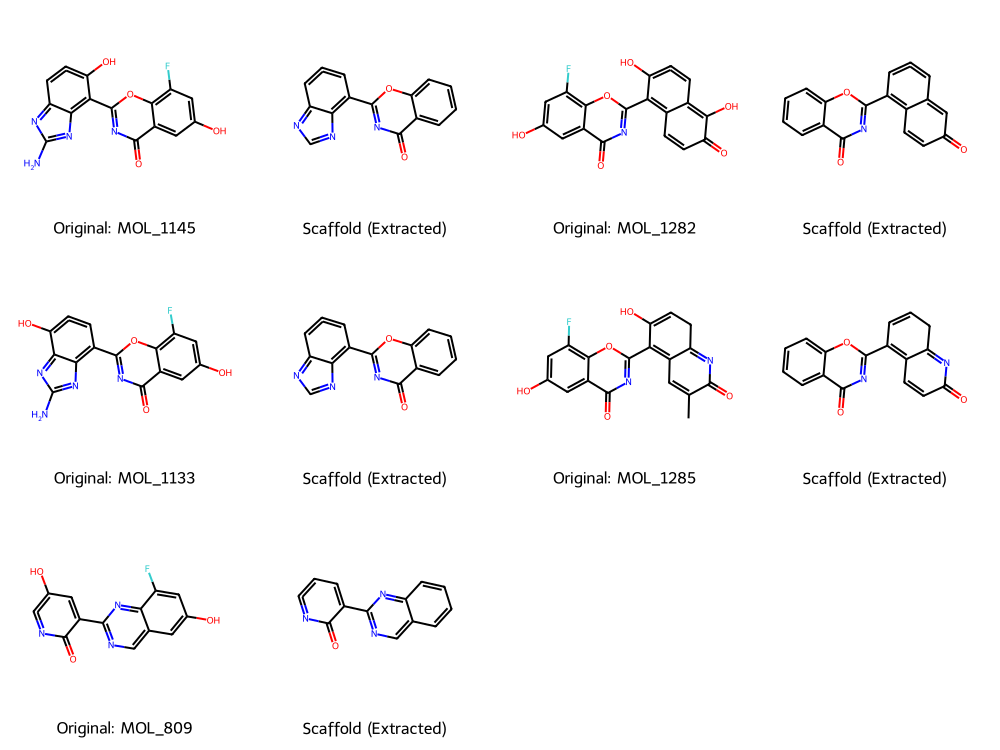

In [31]:
# [셀 5.5 : 스캐폴드 추출 상태 점검 (수정됨)]

# ▼▼▼ [수정된 부분] 따옴표와 괄호를 닫아주었습니다.
print("--- [셀 5.5] 스캐폴드 추출 상태 점검 ---")

import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Scaffolds import MurckoScaffold

# 1. 현재 확보된 시드 가져오기 (없으면 예시 데이터 사용)
if 'df_verified_seeds' in globals() and not df_verified_seeds.empty:
    check_df = df_verified_seeds.head(10).copy()
    print(f"✅ 현재 확보된 상위 {len(check_df)}개 후보를 검사합니다.")
else:
    # 데이터가 없을 경우를 대비한 예시 (아스피린, 타파미디스)
    print("⚠️ 데이터가 없어 예시(Control)로 테스트합니다.")
    check_df = pd.DataFrame({
        'id': ['Aspirin', 'Tafamidis'],
        'SMILES': ['CC(=O)Oc1ccccc1C(=O)O', 'O=C(O)c1ccc2nc(oc2c1)c1cc(cc(c1)Cl)Cl']
    })

# 2. 비교 이미지 생성 함수
comparison_list = []
legends = []

print("\n--- [Scaffold 추출 상태 점검] ---")

for idx, row in check_df.iterrows():
    mol = Chem.MolFromSmiles(row['SMILES'])
    if not mol: continue
    
    # (1) 스캐폴드 추출
    core = MurckoScaffold.GetScaffoldForMol(mol)
    
    # (2) 너무 작으면 원본 유지하는 로직 적용
    using_original = False
    if core is None or core.GetNumAtoms() < 3:
        core = mol
        using_original = True
        
    # 리스트에 추가 (원본 -> 스캐폴드 순서)
    comparison_list.append(mol)
    comparison_list.append(core)
    
    status = " (Original Used)" if using_original else " (Extracted)"
    legends.append(f"Original: {row['id']}")
    legends.append(f"Scaffold{status}")

# 3. 이미지 그리드로 출력
if comparison_list:
    img = Draw.MolsToGridImage(comparison_list, molsPerRow=4, subImgSize=(250, 250), legends=legends)
    display(img)
else:
    print("표시할 분자가 없습니다.")

In [32]:
# [Debug Cell: 필터링 및 예측 함수 단위 테스트 (수정됨)]
# RESULTS_DIR 자동 감지 기능 추가

import pandas as pd
import os
import glob
import subprocess
from rdkit import Chem
from datetime import datetime

print("🔍 [디버깅 시작] 파이프라인 단위 테스트...")

# --- 0. RESULTS_DIR 경로 자동 설정 (에러 방지) ---
if 'MAIN_RESULTS_DIR' in globals():
    RESULTS_DIR = MAIN_RESULTS_DIR
    print(f"  > 글로벌 설정 감지: {RESULTS_DIR}")
elif 'RESULTS_DIR' in globals():
    print(f"  > 기존 설정 유지: {RESULTS_DIR}")
else:
    # 가장 최근에 만들어진 cycling_pipeline 폴더 찾기
    candidates = sorted(glob.glob("./cycling_pipeline_results_*"), key=os.path.getmtime)
    if candidates:
        RESULTS_DIR = candidates[-1]
        print(f"  > 최근 폴더 자동 선택: {RESULTS_DIR}")
    else:
        # 그것도 없으면 임시 폴더 생성
        RESULTS_DIR = "./debug_temp_results"
        os.makedirs(RESULTS_DIR, exist_ok=True)
        print(f"  > 임시 폴더 생성: {RESULTS_DIR}")

# ----------------------------------------------------------------
# 1. 가짜(Mock) 데이터 생성
# ----------------------------------------------------------------
# (1) Tafamidis (Pass해야 함)
# (2) Aspirin (Fail 예상 - 점수 낮음)
# (3) Random Evo Molecule (테스트용)
debug_data = [
    {"id": "Control_Tafamidis", "SMILES": "O=C(O)c1ccc2nc(oc2c1)c1cc(cc(c1)Cl)Cl"},
    {"id": "Control_Aspirin",   "SMILES": "CC(=O)Oc1ccccc1C(=O)O"},
    {"id": "Test_Evo_1",        "SMILES": "CC1=CC=C(C=C1)NC(=O)C2=CC(=CC(=C2)Cl)Cl"} 
]
df_debug = pd.DataFrame(debug_data)

# 테스트용 서브 폴더 생성
debug_dir = os.path.join(RESULTS_DIR, "debug_test_unit")
os.makedirs(debug_dir, exist_ok=True)
print(f"  > 테스트 데이터: {len(df_debug)}개")
print(f"  > 디버그 저장소: {debug_dir}")

# ----------------------------------------------------------------
# 2. RDKit 테스트
# ----------------------------------------------------------------
print("\n[Test 1] RDKit 속성 계산...")
try:
    # 만약 calculate_rdkit_properties 함수가 정의 안되어 있으면 에러 나므로 체크
    if 'calculate_rdkit_properties' not in globals():
        raise NameError("calculate_rdkit_properties 함수가 없습니다. [셀 3]을 먼저 실행하세요.")
        
    df_debug = calculate_rdkit_properties(df_debug)
    
    # 결과 출력
    if 'pass_rdkit' in df_debug.columns:
        display(df_debug[['id', 'MW', 'LogP', 'pass_rdkit']])
        print("  ✅ RDKit 테스트 완료.")
    else:
        print("  ❌ pass_rdkit 컬럼 생성 실패")

except Exception as e:
    print(f"  ❌ RDKit 테스트 실패: {e}")

# ----------------------------------------------------------------
# 3. ADMET 예측 테스트
# ----------------------------------------------------------------
print("\n[Test 2] ADMET 예측 (외부 스크립트 실행)...")
admet_in = os.path.join(debug_dir, "debug_admet_in.csv")
admet_out = os.path.join(debug_dir, "debug_admet_out.csv")

try:
    if os.path.exists(admet_out): os.remove(admet_out)
    
    # run_admet_prediction 함수 호출
    df_debug = run_admet_prediction(df_debug, admet_in, admet_out)
    
    # 결과 확인
    if 'hERG_prob' in df_debug.columns:
        print("  > ADMET 결과 컬럼 확인됨.")
        display(df_debug[['id', 'hERG_prob', 'AqSolDB_pred', 'pass_admet']])
        
        # 데이터 타입 확인
        if df_debug['hERG_prob'].dtype == 'object':
            print("  ⚠️ [경고] hERG_prob가 문자열(Object)입니다. [셀 3]의 숫자 변환 로직을 확인하세요.")
    else:
        print("  ❌ hERG_prob 컬럼이 생성되지 않았습니다.")
        if os.path.exists(admet_out):
            print("  🔻 생성된 CSV 내용 (상위 3줄):")
            with open(admet_out, 'r') as f:
                print(f.read(300))
                
except Exception as e:
    print(f"  ❌ ADMET 테스트 실패: {e}")

# ----------------------------------------------------------------
# 4. ML Affinity 예측 테스트
# ----------------------------------------------------------------
print("\n[Test 3] Binding Affinity ML 예측...")
ml_in = os.path.join(debug_dir, "debug_ml_in.csv")

try:
    # 강제로 3개 다 넣어서 테스트
    df_aff_test = df_debug.copy()
    
    # run_ml_affinity 함수 호출
    df_aff_test = run_ml_affinity(df_aff_test, ml_in, debug_dir)
    
    # 타겟 컬럼 확인
    target_name = RECEPTORS_CONFIG[0]["name"] if 'RECEPTORS_CONFIG' in globals() else "MT_V30M"
    target_col = f'pKd_ML_{target_name}'
    
    if target_col in df_aff_test.columns:
        print(f"  > Affinity 결과 컬럼 확인됨: {target_col}")
        display(df_aff_test[['id', target_col, 'pass_ml_affinity']])
        
        # Tafamidis 값 확인
        row = df_aff_test[df_aff_test['id']=='Control_Tafamidis']
        if not row.empty:
            val = row[target_col].values[0]
            print(f"  > Tafamidis 예측 점수: {val}")
        else:
            print("  ⚠️ Tafamidis 행이 사라졌습니다.")
    else:
        print(f"  ❌ Affinity 컬럼({target_col}) 미생성. (모델 실행 실패 가능성)")
        # 임시 파일 확인
        temp_files = glob.glob(os.path.join(debug_dir, "temp_*.csv"))
        if temp_files:
            print(f"  🔻 잔존 임시 파일 ({len(temp_files)}개):")
            for tf in temp_files[:2]:
                print(f"     - {os.path.basename(tf)}")

except Exception as e:
    print(f"  ❌ Affinity 테스트 실패: {e}")

print("\n🔍 [디버깅 종료]")

🔍 [디버깅 시작] 파이프라인 단위 테스트...
  > 글로벌 설정 감지: ./cycling_pipeline_results_20251122_184913
  > 테스트 데이터: 3개
  > 디버그 저장소: ./cycling_pipeline_results_20251122_184913/debug_test_unit

[Test 1] RDKit 속성 계산...
  [2] RDKit 물리화학적 속성 및 특허성(Tanimoto) 계산...
  [2] RDKit 필터 통과: 1 / 3


,id,MW,LogP,pass_rdkit
0,Control_Tafamidis,308.120,4.49980,True
1,Control_Aspirin,180.159,1.31010,False
2,Test_Evo_1,280.154,4.55412,False


  ✅ RDKit 테스트 완료.

[Test 2] ADMET 예측 (외부 스크립트 실행)...
  [3] ADMET (ML) 예측...
  [3] ADMET 필터 통과: 1 / 3
  > ADMET 결과 컬럼 확인됨.


,id,hERG_prob,AqSolDB_pred,pass_admet
0,Control_Tafamidis,0.701574,-4.970232,False
1,Control_Aspirin,0.283618,-1.897502,True
2,Test_Evo_1,0.829776,-5.146430,False



[Test 3] Binding Affinity ML 예측...
  [4] Binding Affinity 예측...
  [4] ML Affinity 필터 통과: 0 / 3
  > Affinity 결과 컬럼 확인됨: pKd_ML_MT_V30M


,id,pKd_ML_MT_V30M,pass_ml_affinity
0,Control_Tafamidis,5.323033,False
1,Control_Aspirin,4.186767,False
2,Test_Evo_1,5.245633,False


  > Tafamidis 예측 점수: 5.323033333333334

🔍 [디버깅 종료]


In [42]:
# [셀 6: 🧬 진화 루프 (Scaffold-Based Decoration) - Complete Version]
# 핵심 뼈대(Scaffold)는 유지하고, 안전한 작용기(R-group)만 붙여서 최적화합니다.

import pandas as pd
import os
import random
import time
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

print("--- [셀 6] 진화적 보충 시작 (Strategy: Enhanced Scaffold Decoration) ---")

# ==============================================================================
# ★★★ 필터링 기준 설정 (Global Variable Overwrite) ★★★
# ==============================================================================
ML_AFFINITY_POTENCY_THRESH = 6.0 
if 'G_POTENCY_THRESH' in globals() and G_POTENCY_THRESH is not None:
    G_POTENCY_THRESH = max(G_POTENCY_THRESH, 6.0)
else:
    G_POTENCY_THRESH = 6.0

QED_MIN = 0.6
SA_SCORE_MAX = 6.0

# ★★★ [추가] 놓친 기준들 명시 ★★★
LLE_MIN = 2.0         # 최소 효율성 (진화 중에는 2.0, 최종 선별땐 3.0 권장)
HERG_PROB_MAX = 0.5   # 독성 커트라인
AQSOL_PRED_MIN = -5.0 # 용해도 커트라인

print(f"✅ 적용된 진화 필터 기준 (Full):")
print(f"   - ML pKd > {ML_AFFINITY_POTENCY_THRESH}")
print(f"   - Gnina pKd > {G_POTENCY_THRESH}")
print(f"   - LLE (효율) >= {LLE_MIN}")  # ◀ 확인!
print(f"   - QED >= {QED_MIN}")
print(f"   - SA Score <= {SA_SCORE_MAX}")
print(f"   - hERG Prob <= {HERG_PROB_MAX}") # ◀ 확인!
print("="*60)

# --- 0. 초기화 ---
TARGET_FINAL_COUNT = 10 # 목표 개수
if 'df_verified_seeds' not in globals() or df_verified_seeds.empty:
    print("⚠️ 시드가 없습니다. 빈 풀에서 시작합니다.")
    current_pool = pd.DataFrame(columns=['id', 'SMILES'])
else:
    current_pool = df_verified_seeds.copy()

# 중복 방지용 Set (Canonical SMILES 기준)
try:
    tried_smiles = set([Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) for s in current_pool['SMILES'] if Chem.MolFromSmiles(s)])
except:
    tried_smiles = set()
    
print(f"   🏁 초기 부모 풀: {len(current_pool)} 개")

# --- 1. 약물화학적으로 안전한 작용기(R-group) 라이브러리 ---
SAFE_R_GROUPS = ['C', 'O', 'N', 'F', 'Cl', 'OC', 'C(=O)C', 'CN', 'CF']

def decorate_scaffold(mol):
    if mol is None: return None
    try:
        rw_mol = Chem.RWMol(mol)
        attachable_indices = [atom.GetIdx() for atom in rw_mol.GetAtoms() if atom.GetAtomicNum() == 6 and atom.GetTotalNumHs() > 0]
        if not attachable_indices: return None 

        idx_to_attach = random.choice(attachable_indices)
        r_group_smiles = random.choice(SAFE_R_GROUPS)
        
        bond_type = Chem.BondType.SINGLE
        atom_to_add = None
        
        if r_group_smiles == 'C': atom_to_add = Chem.Atom(6)
        elif r_group_smiles == 'O': atom_to_add = Chem.Atom(8)
        elif r_group_smiles == 'N': atom_to_add = Chem.Atom(7)
        elif r_group_smiles == 'F': atom_to_add = Chem.Atom(9)
        elif r_group_smiles == 'Cl': atom_to_add = Chem.Atom(17)
        else: atom_to_add = Chem.Atom(6)
        
        if atom_to_add:
            new_idx = rw_mol.AddAtom(atom_to_add)
            rw_mol.AddBond(idx_to_attach, new_idx, bond_type)

        new_mol = rw_mol.GetMol()
        Chem.SanitizeMol(new_mol)
        return new_mol
    except:
        return None

# --- 2. 진화 생성 함수 ---
def run_evolutionary_generation(df_hits, target_count=100, history_set=set()):
    generated_smiles = set()
    mols = [Chem.MolFromSmiles(s) for s in df_hits['SMILES'] if Chem.MolFromSmiles(s)]
    if not mols: return pd.DataFrame()

    attempts = 0
    
    print(f"      시작: {len(mols)}개 부모 분자로부터 {target_count}개 목표 생성")
    
    while len(generated_smiles) < target_count and attempts < target_count * 50:
        attempts += 1
        parent = random.choice(mols)
        child = decorate_scaffold(parent)
        
        if child:
            try:
                # Canonical SMILES로 변환하여 중복 정밀 체크
                smi = Chem.MolToSmiles(child, canonical=True, isomericSmiles=True)
                
                if 8 <= child.GetNumAtoms() <= 60 and 200 <= Descriptors.MolWt(child) <= 500:
                    if smi not in history_set and smi not in generated_smiles:
                        generated_smiles.add(smi)
                        if len(generated_smiles) % 50 == 0:
                            print(f"        생성 진행: {len(generated_smiles)}/{target_count}")
            except: pass
        
        if attempts % 2000 == 0:
            print(f"        시도: {attempts}, 성공: {len(generated_smiles)}")

    print(f"      완료: {len(generated_smiles)}개 생성 (총 {attempts}회 시도)")

    data = [{'SMILES': s, 'source': 'evolution'} for s in generated_smiles]
    if not data: return pd.DataFrame()
    
    df_gen = pd.DataFrame(data)
    ts = str(time.time_ns())[-6:]
    df_gen['id'] = [f"evo_{ts}_{i}" for i in df_gen.index]
    return df_gen

# --- 3. 진화 루프 실행 (Full Logic) ---
cycle_num = 1
MAX_CYCLES = 30
best_score_history = []  # 점수 기록용

while len(current_pool) < TARGET_FINAL_COUNT and cycle_num <= MAX_CYCLES:
    print(f"\n   🧬 [Cycle {cycle_num}] 확보: {len(current_pool)} / {TARGET_FINAL_COUNT}")
    evo_dir = os.path.join(MAIN_RESULTS_DIR, f"evo_{cycle_num}")
    os.makedirs(evo_dir, exist_ok=True)
    
    # A. 생성 (Generation)
    generation_size = max(200, 100 * cycle_num)
    # ★ 여기가 이전에 주석 처리되어 실행되지 않았던 부분입니다.
    df_offspring = run_evolutionary_generation(current_pool, target_count=generation_size, history_set=tried_smiles)
    
    if df_offspring.empty:
        print("      ⚠️ 생성 가능한 유효 구조가 고갈되었습니다.")
        break

    current_batch_smiles = set(df_offspring['SMILES'])
    tried_smiles.update(current_batch_smiles)
    
    # B. 필터링 (Filtering)
    # ★ 여기가 이전에 주석 처리되어 실행되지 않았던 부분입니다.
    print(f"      📊 필터링 파이프라인 시작...")
    _, df_survivors = run_filtering_cascade(
        df_offspring, evo_dir, f"evo_{cycle_num}", gnina_input_dir, receptor_pdbqt_dir
    )
    
    # C. 업데이트 (Update) - [수정됨: LLE 및 hERG 2차 정밀 검사 추가]
    if not df_survivors.empty:
        # ----------------------------------------------------------------------
        # ★★★ [추가] 안전장치: LLE 및 hERG 기준으로 2차 컷오프 (Double Check) ★★★
        # ----------------------------------------------------------------------
        
        # 1. LLE 계산 (만약 누락되어 있다면)
        gnina_col = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
        if 'LLE' not in df_survivors.columns and 'LogP' in df_survivors.columns and gnina_col in df_survivors.columns:
            df_survivors['LLE'] = df_survivors[gnina_col] - df_survivors['LogP']
        
        # 2. 필터 조건 설정 (값이 없으면 통과시킨다고 가정하고 조건문 작성)
        # LLE가 계산되어 있으면 LLE_MIN(2.0) 이상이어야 함
        cond_lle = df_survivors['LLE'] >= LLE_MIN if 'LLE' in df_survivors.columns else True
        
        # hERG가 계산되어 있으면 HERG_PROB_MAX(0.5) 이하여야 함
        cond_herg = df_survivors['hERG_prob'] <= HERG_PROB_MAX if 'hERG_prob' in df_survivors.columns else True
        
        # 3. 최종 생존자 선별
        real_survivors = df_survivors[cond_lle & cond_herg].copy()
        
        # 탈락자 수 확인 (로그용)
        drop_count = len(df_survivors) - len(real_survivors)
        if drop_count > 0:
            print(f"      ⚠️ 주의: Gnina 점수는 좋았으나 {drop_count}개가 LLE/독성 기준 미달로 추가 탈락함.")

        # ----------------------------------------------------------------------
        # 기존 업데이트 로직 (대상: real_survivors)
        # ----------------------------------------------------------------------
        if not real_survivors.empty:
            new_hits = real_survivors.reset_index()
            current_pool = pd.concat([current_pool, new_hits], ignore_index=True)
            
            # 최고 점수 기록 (Gnina pKd 기준)
            if gnina_col in new_hits.columns:
                best_score = new_hits[gnina_col].max()
                best_score_history.append((cycle_num, best_score))
                print(f"      🎉 신규 생존: {len(new_hits)}개! (최고 점수: {best_score:.3f}, 누적: {len(current_pool)})")
            else:
                best_score_history.append((cycle_num, 0.0)) # 점수 컬럼 없으면 0 처리
                print(f"      🎉 신규 생존: {len(new_hits)}개! (누적: {len(current_pool)})")
        else:
            print("      ❌ 생존자 없음 (모두 LLE/독성 2차 심사에서 탈락 -> 다음 사이클 시도)")
            # 기록 유지 (이전 점수 복사)
            if best_score_history:
                best_score_history.append((cycle_num, best_score_history[-1][1]))
            else:
                best_score_history.append((cycle_num, 0.0))
            
    else:
        print("      ❌ 생존자 없음 (1차 필터링 기준이 높음 -> 다음 사이클 시도)")
        # 기록 유지 (이전 점수 복사)
        if best_score_history:
            best_score_history.append((cycle_num, best_score_history[-1][1]))
        else:
            best_score_history.append((cycle_num, 0.0))
        
    cycle_num += 1

# --- 4. 저장 ---
FINAL_PATH = os.path.join(MAIN_RESULTS_DIR, "FINAL_EVOLVED_CANDIDATES.csv")
current_pool.to_csv(FINAL_PATH, index=False)

print(f"\n🎉 최종 완료. 총 {len(current_pool)}개 후보 생성.")
if not current_pool.empty:
    col_mt = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
    if col_mt in current_pool.columns:
        display(current_pool.sort_values(by=col_mt, ascending=False).head(10))

--- [셀 6] 진화적 보충 시작 (Strategy: Enhanced Scaffold Decoration) ---
✅ 적용된 진화 필터 기준 (Full):
   - ML pKd > 6.0
   - Gnina pKd > 6.0
   - LLE (효율) >= 2.0
   - QED >= 0.6
   - SA Score <= 6.0
   - hERG Prob <= 0.5
   🏁 초기 부모 풀: 5 개

   🧬 [Cycle 1] 확보: 5 / 10
      시작: 5개 부모 분자로부터 200개 목표 생성
        생성 진행: 50/200
        생성 진행: 100/200
        시도: 2000, 성공: 104
        시도: 4000, 성공: 104
        시도: 6000, 성공: 104
        시도: 8000, 성공: 104
        시도: 10000, 성공: 104
      완료: 104개 생성 (총 10000회 시도)
      📊 필터링 파이프라인 시작...
   CASCADE [evo_1] 필터링 시작 (104개)
  [2] RDKit 물리화학적 속성 및 특허성(Tanimoto) 계산...
  [2] RDKit 필터 통과: 37 / 104
  [3] ADMET (ML) 예측...
  [3] ADMET 필터 통과: 34 / 37
  [4] Binding Affinity 예측...
  [4] ML Affinity 필터 통과: 32 / 34
   🚀 Gnina 도킹 대상: 32개


   ⏳ Gnina Docking Progress:   0%|          | 0/64 [00:00<?, ?it/s]

      🎉 신규 생존: 29개! (최고 점수: 8.037, 누적: 34)

🎉 최종 완료. 총 34개 후보 생성.


,SMILES,id,pKd_ML_MT_V30M,pKd_ML_TTR_WT,hERG_prob,hERG_flag,CYP3A4_prob,CYP3A4_flag,AqSolDB_pred,LogP,...,MW,HBD,HBA,TPSA,RotB,PAINS_Alerts,pass_rdkit,pass_admet,pass_ml_affinity,pass_final
17,CC1=CC2=C(c3nc(=O)c4cc(O)c(Cl)c(F)c4o3)C(O)=CC...,evo_888491_39,6.106000,5.912200,0.356366,0,0.358126,0,-3.574724,3.21280,...,388.738,2.0,6.0,112.99,1.0,0.0,True,True,True,True
32,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=...,evo_888491_102,6.408067,6.158200,0.253445,0,0.141840,0,-4.117249,2.73800,...,367.288,3.0,7.0,120.86,1.0,0.0,True,True,True,True
9,CC1=CC2=C(c3nc(=O)c4c(C)c(O)cc(F)c4o3)C(O)=CCC...,evo_888491_20,6.038167,5.830033,0.324434,0,0.354624,0,-3.718300,2.86782,...,368.320,2.0,6.0,112.99,1.0,0.0,True,True,True,True
1,O=C1C=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC...,MOL_1282,6.285000,6.112000,0.246000,0,0.165000,0,-3.669000,2.34800,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19,Cc1c(O)cc(F)c2oc(C3=C4C=CC(=O)C(O)=C4C=C=C3O)n...,evo_888491_42,6.408767,6.158633,0.249386,0,0.168222,0,-4.080337,2.65632,...,367.288,3.0,7.0,120.86,1.0,0.0,True,True,True,True
12,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C(C)CC...,evo_888491_26,6.095400,5.826500,0.329951,0,0.398872,0,-3.834164,2.94950,...,368.320,2.0,6.0,112.99,1.0,0.0,True,True,True,True
29,CC1=CC2=C(c3nc(=O)c4cc(O)c(F)c(F)c4o3)C(O)=CCC...,evo_888491_84,6.194833,5.982467,0.322550,0,0.338797,0,-3.241210,2.69850,...,372.283,2.0,6.0,112.99,1.0,0.0,True,True,True,True
14,O=C1N=C2CC=C(O)C(c3nc(=O)c4cc(O)cc(F)c4o3)=C2C...,evo_888491_34,6.155700,5.909567,0.415761,0,0.475697,0,-3.822788,2.77830,...,388.738,2.0,6.0,112.99,2.0,0.0,True,True,True,True
10,CC1=CC2=C(c3nc(=O)c4c(Cl)c(O)cc(F)c4o3)C(O)=CC...,evo_888491_24,6.106367,5.914933,0.356144,0,0.355200,0,-3.842052,3.21280,...,388.738,2.0,6.0,112.99,1.0,0.0,True,True,True,True
31,O=C1C=CC2=C(c3nc(=O)c4c(Cl)c(O)cc(F)c4o3)C(O)=...,evo_888491_90,6.431767,6.251367,0.274398,0,0.173471,0,-4.204426,3.00130,...,387.706,3.0,7.0,120.86,1.0,0.0,True,True,True,True


In [61]:
import pandas as pd
import numpy as np
import os

print("--- [셀 7] 최종 후보 선별 및 상세 성적표 (Tafamidis 비교 포함) ---")

# --- 1. 데이터 준비 ---
# A. 후보 물질 데이터 로드
try:
    if 'current_pool' in globals() and not current_pool.empty:
        df_candidates = current_pool.copy()
    else:
        res_path = os.path.join(MAIN_RESULTS_DIR, "FINAL_EVOLVED_CANDIDATES.csv")
        df_candidates = pd.read_csv(res_path)
    print(f"   > 후보 풀 로드: {len(df_candidates)}개")
except:
    df_candidates = pd.DataFrame()

# B. 대조군(Tafamidis) 데이터 가져오기
tafa_row = pd.DataFrame()
try:
    if 'df_controls_baseline' in globals() and not df_controls_baseline.empty:
        # 인덱스가 id로 되어있을 수 있으므로 reset_index
        temp_ctrl = df_controls_baseline.reset_index() if 'id' not in df_controls_baseline.columns else df_controls_baseline.copy()
        tafa_row = temp_ctrl[temp_ctrl['id'] == 'LIG_Tafamidis'].copy()
        
        # Tanimoto (자기 자신이므로 1.0)
        tafa_row['Tanimoto_vs_Tafamidis'] = 1.0
        # Source 표시
        tafa_row['Source'] = 'Reference (Control)'
    else:
        print("   ⚠️ 대조군 데이터(df_controls_baseline)가 메모리에 없습니다.")
except Exception as e:
    print(f"   ⚠️ 대조군 로드 실패: {e}")

if not df_candidates.empty:
    col_mt = f"Gnina_pKd_{RECEPTORS_CONFIG[0]['name']}"
    df_candidates['Source'] = 'AI_Generated'

    # (1) 누락된 컬럼 0 처리 (안전장치)
    req_cols = ['QED', 'SA_Score', 'Tanimoto_vs_Tafamidis', 'hERG_prob', 'LogP']
    for col in req_cols:
        if col not in df_candidates.columns:
            df_candidates[col] = 0 if col != 'SA_Score' else 10

    # (2) LLE 재계산 (pKd - LogP)
    if 'LLE' not in df_candidates.columns:
        df_candidates['LLE'] = df_candidates[col_mt] - df_candidates['LogP']

    # --- 2. 필터링 기준 적용 ---
    TAFA_PKD = G_POTENCY_THRESH if 'G_POTENCY_THRESH' in globals() else 6.0
    
    MIN_PKD = TAFA_PKD * 0.95    
    MIN_LLE = 2.5                
    MIN_QED = 0.5                
    MAX_SA = 6.0                 
    MAX_HERG = 0.5               
    
    print(f"   > 컷오프 기준: pKd>{MIN_PKD:.1f}, LLE>{MIN_LLE}, QED>{MIN_QED}, SA<{MAX_SA}, hERG<{MAX_HERG}")

    # 필터링
    mask = (
        (df_candidates[col_mt] >= MIN_PKD) &
        (df_candidates['LLE'] >= MIN_LLE) &
        (df_candidates['QED'] >= MIN_QED) &
        (df_candidates['SA_Score'] <= MAX_SA) &
        (df_candidates['hERG_prob'] <= MAX_HERG)
    )
    
    df_top_hits = df_candidates[mask].copy()
    
    # 구조대(Rescue)
    if df_top_hits.empty:
        print("\n⚠️ [Rescue] 엄격한 기준 통과자 없음. 완화된 기준 적용.")
        mask_relaxed = (
            (df_candidates[col_mt] >= MIN_PKD * 0.9) &
            (df_candidates['LLE'] >= 2.0)
        )
        df_top_hits = df_candidates[mask_relaxed].copy()

    # 정렬: LLE 높은 순
    df_top_hits_sorted = df_top_hits.sort_values(by='LLE', ascending=False)

    # --- 3. [핵심] Tafamidis와 합치기 ---
    # 필요한 컬럼만 추려서 합침
    common_cols = ['id', 'SMILES', col_mt, 'LogP', 'LLE', 'QED', 'SA_Score', 'hERG_prob', 'Tanimoto_vs_Tafamidis', 'Source']
    
    # Tafamidis 행에도 필요한 컬럼이 있는지 확인하고 채움
    if not tafa_row.empty:
        for c in common_cols:
            if c not in tafa_row.columns:
                tafa_row[c] = np.nan # 없는 값은 NaN 처리
        
        # 합치기 (Tafamidis를 맨 위로)
        df_final_view = pd.concat([tafa_row[common_cols], df_top_hits_sorted[common_cols]], ignore_index=True)
    else:
        df_final_view = df_top_hits_sorted[common_cols]

    print("\n" + "="*80)
    print(f"🎉 최종 리스트 구성 완료 (Total: {len(df_final_view)} rows)")
    print("="*80)

    # --- 4. 상세 성적표 출력 ---
    if not df_final_view.empty:
        display_cols = {
            'id': 'ID',
            'Source': 'Source', # 출처 컬럼 추가
            'SMILES': 'SMILES',
            col_mt: 'Potency (pKd)',      
            'LogP': 'Lipophilicity (LogP)', 
            'LLE': 'Efficiency (LLE)',    
            'QED': 'Drug-like (QED)',     
            'SA_Score': 'Synth (SA)',     
            'hERG_prob': 'Toxicity (hERG)', 
            'Tanimoto_vs_Tafamidis': 'Similarity (vs Tafa)' 
        }
        
        df_report = df_final_view.rename(columns=display_cols)
        
        print("\n📊 [최종 후보 상세 스펙 리스트 (Top 20)]")
        print("   * 맨 윗줄의 Reference(Control)와 비교해보세요.")

        try:
            # 스타일링: Tafamidis 행은 굵게 혹은 배경색 처리 등은 어렵지만, Source로 구분됨
            styled_df = df_report.head(21).style.background_gradient(
                subset=['Efficiency (LLE)', 'Drug-like (QED)'], cmap='Greens'
            ).background_gradient(
                subset=['Synth (SA)', 'Toxicity (hERG)'], cmap='Reds'
            ).format({
                'Potency (pKd)': '{:.2f}',
                'Lipophilicity (LogP)': '{:.2f}',
                'Efficiency (LLE)': '{:.2f}',
                'Drug-like (QED)': '{:.2f}',
                'Synth (SA)': '{:.2f}',
                'Toxicity (hERG)': '{:.3f}',
                'Similarity (vs Tafa)': '{:.2f}' 
            })
            display(styled_df)
        except:
            display(df_report.head(21))

        # 파일 저장
        save_path = os.path.join(MAIN_RESULTS_DIR, "FINAL_TOP_CANDIDATES_WITH_CONTROL.csv")
        df_report.to_csv(save_path, index=False)
        print(f"\n💾 리포트 저장 완료: {save_path}")

    else:
        print("❌ 표시할 데이터가 없습니다.")

--- [셀 7] 최종 후보 선별 및 상세 성적표 (Tafamidis 비교 포함) ---
   > 후보 풀 로드: 34개
   > 컷오프 기준: pKd>5.7, LLE>2.5, QED>0.5, SA<6.0, hERG<0.5

🎉 최종 리스트 구성 완료 (Total: 34 rows)

📊 [최종 후보 상세 스펙 리스트 (Top 20)]
   * 맨 윗줄의 Reference(Control)와 비교해보세요.


,ID,SMILES,Potency (pKd),Lipophilicity (LogP),Efficiency (LLE),Drug-like (QED),Synth (SA),Toxicity (hERG),Similarity (vs Tafa),Source
0,LIG_Tafamidis,OC(O)C1CC[C@H]2N[C@@H](C3CC(Cl)CC(Cl)C3)OC2C1,5.27,1.80,3.47,0.54,5.13,0.672,1.00,Reference (Control)
1,MOL_1145,NC1=NC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=N1,7.07,1.12,5.94,0.67,4.12,0.138,0.14,AI_Generated
2,MOL_1282,O=C1C=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=C1O,7.85,2.35,5.50,0.67,3.91,0.246,0.14,AI_Generated
3,MOL_1133,NC1=NC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C=C=C(O)C2=N1,6.51,1.12,5.39,0.67,4.07,0.139,0.14,AI_Generated
4,evo_888491_102,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=C(O)C1=O,7.97,2.74,5.23,0.66,3.96,0.253,0.13,AI_Generated
5,evo_888491_42,Cc1c(O)cc(F)c2oc(C3=C4C=CC(=O)C(O)=C4C=C=C3O)nc(=O)c12,7.76,2.66,5.11,0.66,4.01,0.249,0.14,AI_Generated
6,evo_888491_20,CC1=CC2=C(c3nc(=O)c4c(C)c(O)cc(F)c4o3)C(O)=CCC2=NC1=O,7.95,2.87,5.08,0.80,3.76,0.324,0.14,AI_Generated
7,evo_888491_36,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=CC(F)C2=NC1=O,7.44,2.51,4.93,0.80,4.28,0.330,0.13,AI_Generated
8,evo_888491_84,CC1=CC2=C(c3nc(=O)c4cc(O)c(F)c(F)c4o3)C(O)=CCC2=NC1=O,7.62,2.70,4.93,0.80,3.76,0.323,0.13,AI_Generated
9,evo_888491_39,CC1=CC2=C(c3nc(=O)c4cc(O)c(Cl)c(F)c4o3)C(O)=CCC2=NC1=O,8.04,3.21,4.82,0.78,3.81,0.356,0.16,AI_Generated



💾 리포트 저장 완료: ./cycling_pipeline_results_20251122_184913/FINAL_TOP_CANDIDATES_WITH_CONTROL.csv


In [43]:
# [셀 7: 🥇 최종 후보 선별 및 상세 성적표 (Full Report Card)]

import pandas as pd
import numpy as np
import os

print("--- [셀 7] 최종 후보 선별 및 상세 성적표 생성 ---")

# --- 1. 데이터 준비 ---
try:
    if 'current_pool' in globals() and not current_pool.empty:
        df_candidates = current_pool.copy()
    else:
        res_path = os.path.join(MAIN_RESULTS_DIR, "FINAL_EVOLVED_CANDIDATES.csv")
        df_candidates = pd.read_csv(res_path)
    print(f"   > 후보 풀 로드: {len(df_candidates)}개")
except:
    print("   ❌ 데이터 없음.")
    df_candidates = pd.DataFrame()

if not df_candidates.empty:
    col_mt = f"Gnina_pKd_{RECEPTORS_CONFIG[0]['name']}"
    
    # (1) 누락된 컬럼 0 처리 (안전장치)
    req_cols = ['QED', 'SA_Score', 'Tanimoto_vs_Tafamidis', 'hERG_prob', 'LogP']
    for col in req_cols:
        if col not in df_candidates.columns:
            df_candidates[col] = 0 if col != 'SA_Score' else 10

    # (2) LLE 재계산 (pKd - LogP)
    if 'LLE' not in df_candidates.columns:
        df_candidates['LLE'] = df_candidates[col_mt] - df_candidates['LogP']

    # --- 2. 필터링 기준 적용 (Book Guidelines) ---
    TAFA_PKD = G_POTENCY_THRESH if 'G_POTENCY_THRESH' in globals() else 6.0
    
    # 기준점 설정
    MIN_PKD = TAFA_PKD * 0.95    # 타파미디스 95% 수준
    MIN_LLE = 2.5                # 효율성 (책 권장 3.0이나 현실적 타협 2.5)
    MIN_QED = 0.5                # 약물성
    MAX_SA = 6.0                 # 합성 난이도
    MAX_HERG = 0.5               # 독성 확률
    
    print(f"   > 컷오프 기준: pKd>{MIN_PKD:.1f}, LLE>{MIN_LLE}, QED>{MIN_QED}, SA<{MAX_SA}, hERG<{MAX_HERG}")

    # 필터링
    mask = (
        (df_candidates[col_mt] >= MIN_PKD) &
        (df_candidates['LLE'] >= MIN_LLE) &
        (df_candidates['QED'] >= MIN_QED) &
        (df_candidates['SA_Score'] <= MAX_SA) &
        (df_candidates['hERG_prob'] <= MAX_HERG)
    )
    
    df_top_hits = df_candidates[mask].copy()
    
    # ★ 구조대(Rescue): 합격자 없으면 기준 완화
    if df_top_hits.empty:
        print("\n⚠️ [Rescue] 엄격한 기준 통과자 없음. LLE > 2.0 으로 완화하여 재검색.")
        mask_relaxed = (
            (df_candidates[col_mt] >= MIN_PKD * 0.9) &
            (df_candidates['LLE'] >= 2.0) &
            (df_candidates['hERG_prob'] <= 0.6)
        )
        df_top_hits = df_candidates[mask_relaxed].copy()

    # 정렬: LLE 높은 순 (Efficiency First)
    df_top_hits_sorted = df_top_hits.sort_values(by='LLE', ascending=False)

    print("\n" + "="*80)
    print(f"🎉 최종 합격 후보: {len(df_candidates)}개 중 {len(df_top_hits_sorted)}개 선발")
    print("="*80)

    # --- 3. [핵심] 상세 성적표 출력 (Detail Report) ---
    if not df_top_hits_sorted.empty:
        # 보고 싶은 컬럼만 선택 및 이름 변경
        display_cols = {
            'id': 'ID',
            'SMILES': 'SMILES',
            col_mt: 'Potency (pKd)',      
            'LogP': 'Lipophilicity (LogP)', 
            'LLE': 'Efficiency (LLE)',    
            'QED': 'Drug-like (QED)',     
            'SA_Score': 'Synth (SA)',     
            'hERG_prob': 'Toxicity (hERG)', 
            # ▼ [수정] Novelty 대신 Similarity로 명확하게 변경
            'Tanimoto_vs_Tafamidis': 'Similarity (vs Tafa)' 
        }
        
        # 존재하는 컬럼만 필터링
        valid_cols = [c for c in display_cols.keys() if c in df_top_hits_sorted.columns]
        df_report = df_top_hits_sorted[valid_cols].rename(columns=display_cols)
        
        # 보기 좋게 출력 (상위 20개)
        print("\n📊 [최종 후보 상세 스펙 리스트 (Top 20)]")
        print("   * LLE(효율)가 높을수록, SA(난이도)와 hERG(독성)가 낮을수록 좋습니다.")
        
        # Pandas 스타일링 (색상 및 포맷) 적용 가능 시 적용
        try:
            styled_df = df_report.head(20).style.background_gradient(
                subset=['Efficiency (LLE)', 'Drug-like (QED)'], cmap='Greens'
            ).background_gradient(
                subset=['Synth (SA)', 'Toxicity (hERG)'], cmap='Reds'
            # ... (중략) ...
            ).format({
                'Potency (pKd)': '{:.2f}',
                'Lipophilicity (LogP)': '{:.2f}',
                'Efficiency (LLE)': '{:.2f}',
                'Drug-like (QED)': '{:.2f}',
                'Synth (SA)': '{:.2f}',
                'Toxicity (hERG)': '{:.3f}',
                # ▼ [수정] 여기도 맞춰주세요
                'Similarity (vs Tafa)': '{:.2f}' 
            })
            display(styled_df)
        except:
            # 스타일링 실패 시 기본 출력
            display(df_report.head(20))

        # 파일 저장
        save_path = os.path.join(MAIN_RESULTS_DIR, "FINAL_TOP_CANDIDATES_FULL_REPORT.csv")
        df_top_hits_sorted.to_csv(save_path, index=False)
        print(f"\n💾 전체 리포트 저장 완료: {save_path}")

    else:
        print("❌ [실패] 완화된 기준조차 통과한 후보가 없습니다. 생성(Cell 6)을 더 돌려보세요.")
        print("   (현재 최고 LLE 후보 5개 스펙 확인)")
        display(df_candidates.sort_values(by='LLE', ascending=False).head(5))

--- [셀 7] 최종 후보 선별 및 상세 성적표 생성 ---
   > 후보 풀 로드: 34개
   > 컷오프 기준: pKd>5.7, LLE>2.5, QED>0.5, SA<6.0, hERG<0.5

🎉 최종 합격 후보: 34개 중 33개 선발

📊 [최종 후보 상세 스펙 리스트 (Top 20)]
   * LLE(효율)가 높을수록, SA(난이도)와 hERG(독성)가 낮을수록 좋습니다.


,ID,SMILES,Potency (pKd),Lipophilicity (LogP),Efficiency (LLE),Drug-like (QED),Synth (SA),Toxicity (hERG),Similarity (vs Tafa)
0,MOL_1145,NC1=NC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=N1,7.07,1.12,5.94,0.67,4.12,0.138,0.14
1,MOL_1282,O=C1C=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=C1O,7.85,2.35,5.50,0.67,3.91,0.246,0.14
2,MOL_1133,NC1=NC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C=C=C(O)C2=N1,6.51,1.12,5.39,0.67,4.07,0.139,0.14
32,evo_888491_102,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=C=CC2=C(O)C1=O,7.97,2.74,5.23,0.66,3.96,0.253,0.13
19,evo_888491_42,Cc1c(O)cc(F)c2oc(C3=C4C=CC(=O)C(O)=C4C=C=C3O)nc(=O)c12,7.76,2.66,5.11,0.66,4.01,0.249,0.14
9,evo_888491_20,CC1=CC2=C(c3nc(=O)c4c(C)c(O)cc(F)c4o3)C(O)=CCC2=NC1=O,7.95,2.87,5.08,0.80,3.76,0.324,0.14
16,evo_888491_36,CC1=CC2=C(c3nc(=O)c4cc(O)cc(F)c4o3)C(O)=CC(F)C2=NC1=O,7.44,2.51,4.93,0.80,4.28,0.330,0.13
29,evo_888491_84,CC1=CC2=C(c3nc(=O)c4cc(O)c(F)c(F)c4o3)C(O)=CCC2=NC1=O,7.62,2.70,4.93,0.80,3.76,0.323,0.13
17,evo_888491_39,CC1=CC2=C(c3nc(=O)c4cc(O)c(Cl)c(F)c4o3)C(O)=CCC2=NC1=O,8.04,3.21,4.82,0.78,3.81,0.356,0.16
14,evo_888491_34,O=C1N=C2CC=C(O)C(c3nc(=O)c4cc(O)cc(F)c4o3)=C2C=C1CCl,7.60,2.78,4.82,0.76,3.81,0.416,0.14



💾 전체 리포트 저장 완료: ./cycling_pipeline_results_20251122_184913/FINAL_TOP_CANDIDATES_FULL_REPORT.csv


In [ ]:
# [셀 8: 📊 최종 결과 요약 및 파일 위치 확인]
# 전체 생성 수, 생존 수, 최종 합격 수를 요약하고 파일 위치를 출력합니다.

import os

print("--- [셀 8] 프로젝트 최종 리포트 ---")

if 'MAIN_RESULTS_DIR' not in globals():
    print("❌ MAIN_RESULTS_DIR 변수가 없습니다. 앞선 셀들을 실행해주세요.")
else:
    # --- 1. 최종 수치 요약 ---
    print("\n📊 [1] 최종 수치 요약")
    print("=" * 40)
    
    # (1) 총 생성 시도
    total_tried = len(tried_smiles) if 'tried_smiles' in globals() else 0
    print(f"1️⃣ 총 생성된 구조 (Raw Generation) : {total_tried} 개")
    
    # (2) 파이프라인 생존자
    total_survivors = len(current_pool) if 'current_pool' in globals() else 0
    print(f"2️⃣ 파이프라인 생존자 (Survivors)    : {total_survivors} 개")
    
    # (3) 최종 합격자
    final_hits = len(df_top_hits_sorted) if 'df_top_hits_sorted' in globals() else 0
    print(f"3️⃣ 🥇 최종 합격자 (Final Top Hits)  : {final_hits} 개")
    
    # (4) 선별률
    rate = (final_hits / total_tried * 100) if total_tried > 0 else 0
    print("-" * 40)
    print(f"📉 최종 선별률 (Success Rate)       : {rate:.2f}%")
    print("=" * 40)

    # --- 2. 파일 저장 위치 확인 ---
    print("\n📂 [2] 결과 파일 저장 위치")
    abs_main_dir = os.path.abspath(MAIN_RESULTS_DIR)
    print(f"   👉 전체 폴더: {abs_main_dir}")

    # 최종 리포트 CSV
    final_csv = os.path.join(MAIN_RESULTS_DIR, "FINAL_TOP_CANDIDATES.csv")
    if os.path.exists(final_csv):
        print(f"   👉 최종 합격자 리스트 (CSV): {os.path.basename(final_csv)}")
    else:
        print("   ⚠️ 최종 합격자 파일이 없습니다.")

    # 전체 생존자 CSV
    all_csv = os.path.join(MAIN_RESULTS_DIR, "FINAL_EVOLVED_CANDIDATES.csv")
    if os.path.exists(all_csv):
        print(f"   👉 전체 생존자 리스트 (CSV): {os.path.basename(all_csv)}")

    # --- 3. Top 합격자 3D 파일 위치 추적 ---
    if 'df_top_hits_sorted' in globals() and not df_top_hits_sorted.empty:
        print("\n📦 [3] Top 합격자 3D 구조 파일 위치")
        
        for i in range(min(3, len(df_top_hits_sorted))): # 상위 3개만 예시로 출력
            row = df_top_hits_sorted.iloc[i]
            mol_id = row['id']
            
            # 파일 검색
            found = False
            for root, dirs, files in os.walk(MAIN_RESULTS_DIR):
                for file in files:
                    if mol_id in file and file.endswith(".sdf.gz") and RECEPTORS_CONFIG[0]['name'] in file:
                        print(f"   [{i+1}위] {mol_id}")
                        print(f"       └─ {os.path.abspath(os.path.join(root, file))}")
                        found = True
                        break
                if found: break
            if not found:
                print(f"   [{i+1}위] {mol_id} (파일 못 찾음)")
                
    # --- 4. [추가] 진화 과정 시각화 ---
    print("\n📈 [4] 진화 과정 요약 (Cycle vs Best pKd)")
    print("=" * 40)
    
    # best_score_history 변수가 있는지 확인하고 그래프 그리기
    if 'best_score_history' in globals() and best_score_history:
        for cycle, score in best_score_history:
            # 점수에 비례해서 막대(#) 길이 조절 (예: 6.0점이면 막대 없음, 7.0점이면 #####)
            bar_len = int((score - 6.0) * 10) 
            bar_len = max(0, bar_len) # 음수 방지
            bar = "#" * bar_len
            print(f"   Cycle {cycle:02d}: {score:.3f}  {bar}")
    else:
        print("   (진화 기록이 없습니다)")

    print("\n✅ 모든 작업 완료.")

--- [셀 8] 프로젝트 최종 리포트 ---

📊 [1] 최종 수치 요약
1️⃣ 총 생성된 구조 (Raw Generation) : 109 개
2️⃣ 파이프라인 생존자 (Survivors)    : 34 개
3️⃣ 🥇 최종 합격자 (Final Top Hits)  : 33 개
----------------------------------------
📉 최종 선별률 (Success Rate)       : 30.28%

📂 [2] 결과 파일 저장 위치
   👉 전체 폴더: /home/nudge/Project/drugai/ipynb/cycling_pipeline_results_20251122_184913
   ⚠️ 최종 합격자 파일이 없습니다.
   👉 전체 생존자 리스트 (CSV): FINAL_EVOLVED_CANDIDATES.csv

📦 [3] Top 합격자 3D 구조 파일 위치
   [1위] MOL_1145
       └─ /home/nudge/Project/drugai/ipynb/cycling_pipeline_results_20251122_184913/validation_stage1/MT_V30M_vs_MOL_1145_seed1.sdf.gz
   [2위] MOL_1282
       └─ /home/nudge/Project/drugai/ipynb/cycling_pipeline_results_20251122_184913/validation_stage1/MT_V30M_vs_MOL_1282_seed1.sdf.gz
   [3위] MOL_1133
       └─ /home/nudge/Project/drugai/ipynb/cycling_pipeline_results_20251122_184913/validation_stage1/MT_V30M_vs_MOL_1133_seed1.sdf.gz

📈 [4] 진화 과정 요약 (Cycle vs Best pKd)
   Cycle 01: 8.037  ####################

✅ 모든 작업 완료.


In [64]:
# [셀 9: 📊 최종 Screening Funnel 시각화 (오류 수정됨)]

import pandas as pd
import plotly.express as px

print("--- [셀 9] Screening Funnel 차트 생성 (오류 수정됨) ---")

# 1. 퍼널 데이터 정의
data = {
    'Stage': [
        "1. Initial Generation (Pocket2Mol)",
        "2. PhysChem & Safety Filter (QED/SA/ADMET)",
        "3. High-Throughput Affinity Screening (ML)",
        "4. 3D Structure Verification (Gnina)",
        "5. Scaffold-based Evolution (Generation)",
        "6. Final Selection (Re-filtering)"
    ],
    'Count': [3000, 326, 5, 5, 104, 29],
    'Description': [
        "AI 모델을 통한 대규모 초기 분자 생성",
        "물성, 합성 난이도, 독성/대사 안전성 검증",
        "ML 모델을 이용한 엄격한 결합력 예측",
        "실제 3D 단백질 구조 기반 정밀 도킹 검증",
        "선정된 우수 골격을 기반으로 파생 화합물 추가 생성",
        "생성된 파생 화합물에 대해 모든 검증 재수행"
    ]
}
df = pd.DataFrame(data)

# --- 2. 퍼센트 직접 계산 및 텍스트 포맷팅 ---
retention_rates = ["(100%)"]
label_texts = [f"{df.iloc[0]['Count']}<br>(100%)"]

for i in range(1, len(df)):
    prev_count = df.iloc[i-1]['Count']
    curr_count = df.iloc[i]['Count']
    stage_name = df.iloc[i]['Stage']

    if "Evolution" in stage_name:
        rate_str = "(Generation Phase)"
        final_text = f"{curr_count}<br>{rate_str}"
    else:
        rate = round((curr_count / prev_count) * 100, 1)
        rate_str = f"({rate}%)"
        final_text = f"{curr_count}<br>{rate_str}"

    retention_rates.append(rate_str)
    label_texts.append(final_text)

df['Retention'] = retention_rates
df['Label'] = label_texts

# --- 3. 데이터 역순 정렬 ---
df_reversed = df.iloc[::-1]

# 4. Plotly Funnel Chart 생성
# ★ 중요 수정: 색상 팔레트 설정을 이곳으로 옮겼습니다. ★
fig = px.funnel(df_reversed, x='Count', y='Stage', color='Stage',
                title='<b>AI-Driven Drug Discovery Screening Funnel</b>',
                template="plotly_white",
                text='Label',
                hover_data=['Description', 'Retention'],
                color_discrete_sequence=px.colors.qualitative.Prism) # <-- 여기가 올바른 위치

# 5. 스타일 조정
fig.update_traces(
    textposition="inside",
    textinfo="text",
    marker=dict(line=dict(width=1, color='White')),
    textfont=dict(size=13, color='white', family="Arial Black")
)

# 6. 레이아웃 조정
# ★ 중요 수정: 여기서 잘못된 'colordiscrete_sequence' 속성을 제거했습니다. ★
fig.update_layout(
    showlegend=False,
    title_font_size=24,
    title_x=0.5,
    yaxis_title=None,
    xaxis_title=None,
    xaxis=dict(showticklabels=False, showgrid=False),
    font=dict(family="Arial, sans-serif", size=12),
    height=700,
    margin=dict(l=20, r=20, t=80, b=100)
)

# 7. 최종 결과 강조 주석
fig.add_annotation(
    x=0.5, y=-0.1,
    xref="paper", yref="paper",
    text=f"<b>🎉 Final Result: Total {5 + 29} High-Quality Lead Candidates Discovered</b>",
    showarrow=False,
    font=dict(size=16, color="#ffffff", family="Arial Black"),
    bgcolor="#0052cc",
    bordercolor="#0052cc",
    borderwidth=2,
    borderpad=12,
    align="center"
)

print("✅ 수정된 퍼널 차트 생성 완료. 아래 결과를 확인하세요.")
fig.show()

--- [셀 9] Screening Funnel 차트 생성 (오류 수정됨) ---
✅ 수정된 퍼널 차트 생성 완료. 아래 결과를 확인하세요.


--- [셀 9] 최종 Fix: Synth (SA) 축 복구 및 6축 분석 ---


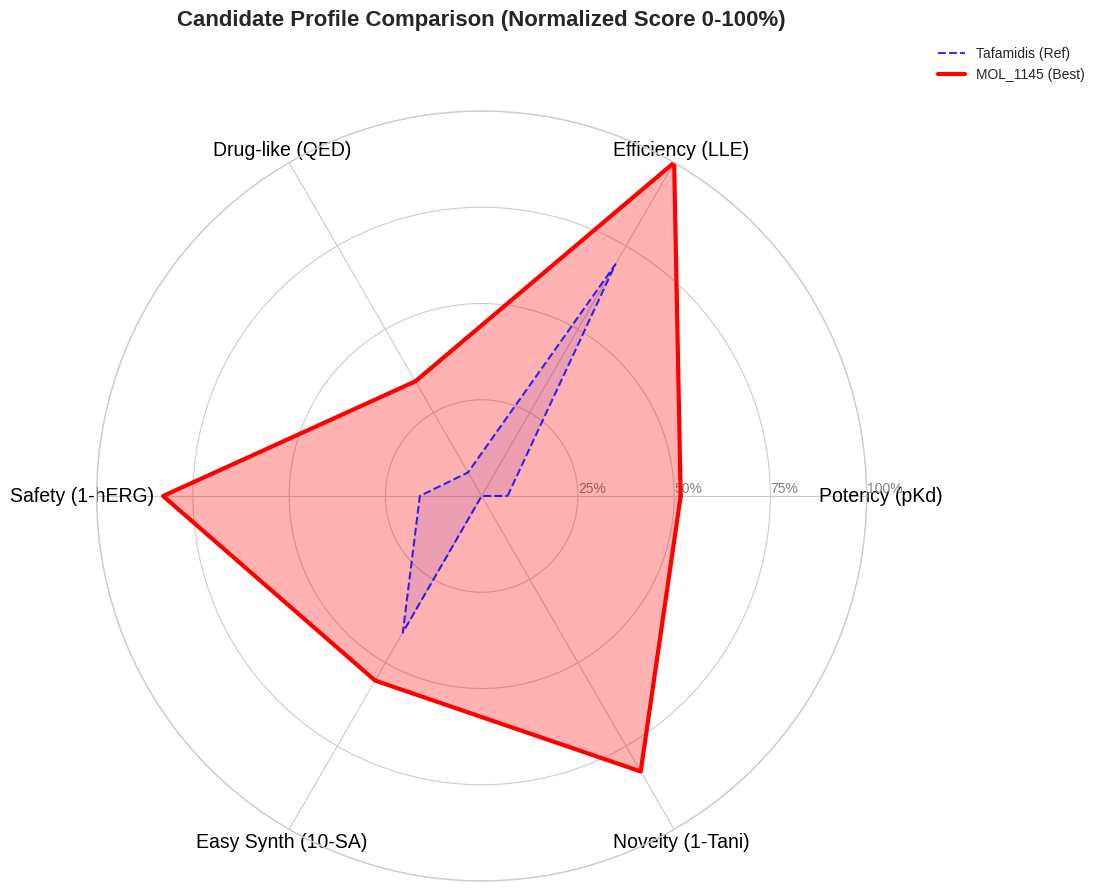


✅ 6축 정규화 Radar Plot 출력 완료.


In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi

print("--- [셀 9] 최종 Fix: Synth (SA) 축 복구 및 6축 분석 ---")

# (이전 셀에서 로드된 df_final, cand_data, ctrl_data, id_col 변수를 사용)

if 'cand_data' in globals() and 'ctrl_data' in globals() and ctrl_data is not None:
    
    # 0. LLE 및 LogP 컬럼 처리 (이전 로직 유지)
    # ---------------------------------------------------------
    cols = df_final.columns
    logp_col = next((c for c in cols if 'logp' in c.lower()), None)
    pkd_col = next((c for c in cols if 'pkd' in c.lower() or 'affinity' in c.lower()), None)
    
    LLE_PRESENT = (logp_col is not None) and (pkd_col is not None)
    if LLE_PRESENT:
        if 'LLE' not in df_final.columns:
            df_final['LLE'] = df_final[pkd_col] - df_final[logp_col]
        # 데이터 갱신 (LLE 계산 후 DataFrame에서 다시 가져옴)
        cand_data = df_final[df_final[id_col].astype(str).str.contains("MOL_1145", case=False)].iloc[0]
        ctrl_data = df_final[df_final[id_col].astype(str).str.contains("Tafa", case=False)].iloc[0]

    # 1. 컬럼 자동 찾기 (유연하게 변경)
    # ---------------------------------------------------------
    qed_col = next((c for c in cols if 'qed' in c.lower()), None)
    herg_col= next((c for c in cols if 'herg' in c.lower()), None)
    sim_col = next((c for c in cols if 'tani' in c.lower() or 'sim' in c.lower()), None)
    
    # 🌟 SA_Score를 'Synth (SA)'로 명시적/유연하게 찾도록 수정
    sa_col_candidates = ['Synth (SA)', 'SA_Score'] 
    
    sa_col = None
    for c in cols:
        # 컬럼 이름의 공백을 제거하고 대소문자를 무시하여 'synth (sa)' 또는 'sa_score'를 찾습니다.
        if c.strip() in sa_col_candidates or c.lower().replace(' ', '') in ['synth(sa)', 'sa_score']:
            sa_col = c
            break

    # 2. 지표별 최적/최악 범위 정의 (Normalization Boundaries)
    # ---------------------------------------------------------
    NORMALIZATION_RANGES = {
        'Potency': (5.0, 9.0, 1),
        'LLE': (0.0, 5.0, 1),
        'QED': (0.5, 1.0, 1),
        'hERG_prob': (0.8, 0.0, -1),
        'SA_Score': (8.0, 1.0, -1), # Lower is Better
        'Tanimoto': (0.8, 0.0, -1)  # Lower is Better (Novelty)
    }
    
    # 3. 정규화 함수 정의 (이전 코드와 동일)
    def normalize_value(value, metric_name, data_source):
        (min_val, max_val, direction) = NORMALIZATION_RANGES[metric_name]
        current_val = data_source.get(metric_name)

        if direction == 1:
            score = (current_val - min_val) / (max_val - min_val)
        else:
            score = (min_val - current_val) / (min_val - max_val)

        return max(0, min(1, score))

    # 4. Radar Plot용 데이터 준비 및 정규화 적용
    # ---------------------------------------------------------
    
    raw_cand_data = {}
    raw_ctrl_data = {}
    
    # 각 지표가 파일에 존재하는 경우에만 raw_data에 추가
    if pkd_col: raw_cand_data['Potency'] = cand_data[pkd_col]; raw_ctrl_data['Potency'] = ctrl_data[pkd_col]
    if LLE_PRESENT: raw_cand_data['LLE'] = cand_data['LLE']; raw_ctrl_data['LLE'] = ctrl_data['LLE']
    if qed_col: raw_cand_data['QED'] = cand_data[qed_col]; raw_ctrl_data['QED'] = ctrl_data[qed_col]
    if herg_col: raw_cand_data['hERG_prob'] = cand_data[herg_col]; raw_ctrl_data['hERG_prob'] = ctrl_data[herg_col]
    
    # ✅ 복구된 SA_Score 사용
    if sa_col: 
        raw_cand_data['SA_Score'] = cand_data[sa_col]; raw_ctrl_data['SA_Score'] = ctrl_data[sa_col]
    else: 
        print("⚠️ SA_Score (Synth (SA)) 컬럼을 찾을 수 없어, Easy Synth 축은 제외됩니다.")
        
    if sim_col: 
        raw_cand_data['Tanimoto'] = cand_data[sim_col]; raw_ctrl_data['Tanimoto'] = ctrl_data[sim_col]
    else: 
        print("⚠️ Tanimoto 컬럼을 찾을 수 없어, Novelty 축은 제외됩니다.")

    # 5. 정규화 및 플로팅
    # ---------------------------------------------------------
    categories_map = {
        'Potency': 'Potency (pKd)', 'LLE': 'Efficiency (LLE)', 'QED': 'Drug-like (QED)', 
        'hERG_prob': 'Safety (1-hERG)', 'SA_Score': 'Easy Synth (10-SA)', 'Tanimoto': 'Novelty (1-Tani)'
    }
    
    categories = []
    normalized_cand = {}; normalized_ctrl = {}
    
    for metric_name in raw_cand_data.keys():
        label = categories_map.get(metric_name, metric_name)
        categories.append(label)
        
        # metric_name이 SA_Score, hERG_prob, Tanimoto일 때, NORMALIZATION_RANGES의 키는 고정된 이름을 사용
        key_name = metric_name if metric_name not in ['QED', 'LLE', 'Potency'] else metric_name 
        
        normalized_cand[label] = normalize_value(raw_cand_data[metric_name], key_name, raw_cand_data)
        normalized_ctrl[label] = normalize_value(raw_ctrl_data[metric_name], key_name, raw_ctrl_data)

    # 6. Radar Plot 그리기 (이전 코드와 동일)
    vals_c = [v * 100 for v in normalized_cand.values()]
    vals_r = [v * 100 for v in normalized_ctrl.values()]
    
    N = len(categories)
    
    if N < 3: 
        print(f"❌ 분석 가능한 축이 {N}개 뿐이어서 Radar Plot을 그릴 수 없습니다.")
    else:
        vals_c += vals_c[:1]; vals_r += vals_r[:1]
        angles = [n / float(N) * 2 * pi for n in range(N)]; angles += angles[:1]
        
        plt.figure(figsize=(10, 10))
        ax = plt.subplot(111, polar=True)
        
        plt.xticks(angles[:-1], categories, color='black', size=14)
        ax.set_rlabel_position(0)
        plt.yticks([25, 50, 75, 100], ["25%", "50%", "75%", "100%"], color="grey", size=10)
        plt.ylim(0, 100)
        
        ax.plot(angles, vals_r, '--', color='blue', label='Tafamidis (Ref)', alpha=0.8)
        ax.fill(angles, vals_r, 'b', alpha=0.1)
        ax.plot(angles, vals_c, '-', color='red', linewidth=3, label='MOL_1145 (Best)')
        ax.fill(angles, vals_c, 'r', alpha=0.3)
        
        plt.title("Candidate Profile Comparison (Normalized Score 0-100%)", y=1.1, size=16, weight='bold')
        plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
        plt.show()
        
        print("\n✅ 6축 정규화 Radar Plot 출력 완료.")

else:
    print("❌ 비교를 위한 데이터가 준비되지 않았습니다. 이전 단계들을 확인해주세요.")

In [36]:
## 구구[셀 8: 🧬 BRICS 기반 적응형 분자 생성 함수 (수정됨)]

from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import BRICS
import random

def run_adaptive_generation_brics(df_hits, target_count=50):
    """
    (수정됨) 히트 분자들을 BRICS 조각으로 분해하고 재조합하여 새로운 분자를 생성합니다.
    random_state가 제거되어 매번 다른 샘플을 생성합니다.
    """
    print(f"   🧬 [적응형 생성] BRICS 기반 변형 생성 시작 (기반 히트: {len(df_hits)}개)...")
    
    generated_molecules_data = []
    
    # --- 1. 히트 분자에서 BRICS 조각 및 Murcko 스캐폴드 추출 ---
    all_brics_fragments = set()
    all_scaffolds = set()
    parent_hit_map = {} # (추적성) 조각 -> 부모 ID

    for _, row in df_hits.iterrows():
        smiles = row['SMILES']
        hit_id = row['id']
        mol = Chem.MolFromSmiles(smiles)
        if not mol:
            continue
         
        # (A) Murcko 스캐폴드 추출
        try:
            scaffold = MurckoScaffold.GetScaffoldForMol(mol)
            scaffold_smiles = Chem.MolToSmiles(scaffold)
            if scaffold_smiles and scaffold_smiles != smiles:
                all_scaffolds.add(scaffold_smiles)
                parent_hit_map[scaffold_smiles] = hit_id
        except:
            pass

        # (B) BRICS 조각 분해
        try:
            fragments = BRICS.BRICSDecompose(mol)
            all_brics_fragments.update(fragments)
            for f_smi in fragments:
                parent_hit_map[f_smi] = hit_id # (단순 추적)
        except:
            pass

    print(f"      > (1/3) 총 {len(all_brics_fragments)}개의 고유 BRICS 조각과 {len(all_scaffolds)}개의 스캐폴드 발견.")

    # --- 2. 추출된 스캐폴드를 생성 목록에 추가 ---
    for smi in all_scaffolds:
        generated_molecules_data.append({
            'SMILES': smi,
            'source': 'scaffold_extraction',
            'parent_id': parent_hit_map.get(smi, 'unknown')
        })

    # --- 3. BRICS 조각 재조합 (Build) ---
    fragment_mols = [Chem.MolFromSmiles(s) for s in all_brics_fragments if Chem.MolFromSmiles(s)]
     
    if len(fragment_mols) > 1:
        print(f"      > (2/3) {len(fragment_mols)}개 조각으로 BRICS 재조합 시도...")
         
        try:
            # (안정성) 최대 분자 크기 제한 (MW ~500)
            built_mols = BRICS.BRICSBuild(fragment_mols, maxDepth=2)
             
            processed_count = 0
            for mol in built_mols:
                if mol:
                    smi = Chem.MolToSmiles(mol)
                    generated_molecules_data.append({
                        'SMILES': smi,
                        'source': 'brics_recombination',
                        'parent_id': 'brics_mix' # (정확한 추적은 어려움)
                    })
                    processed_count += 1
                 
                if processed_count >= target_count * 2: # 너무 많아지는 것 방지
                    break
            print(f"      > (3/3) BRICS 재조합으로 {processed_count}개 분자 생성.")

        except Exception as e:
            print(f"      [경고] BRICS 재조합 실패: {e}")
    else:
         print(f"      > (2/3) BRICS 재조합을 위한 조각이 부족합니다 (2개 이상 필요).")

    # --- 4. 최종 정리 및 반환 ---
    if not generated_molecules_data:
        print("   ❌ [적응형 생성] 생성된 변형 분자가 없습니다.")
        return pd.DataFrame()

    df_generated = pd.DataFrame(generated_molecules_data)
     
    # 유효성 검사 및 중복 제거
    mols = df_generated['SMILES'].apply(Chem.MolFromSmiles)
    df_generated = df_generated[mols.notna()]
    df_generated = df_generated.drop_duplicates(subset=['SMILES']).reset_index(drop=True)
     
    # ID 부여
    unique_timestamp = str(time.time_ns())[-6:]
    df_generated['id'] = [f"adapt_{unique_timestamp}_{i}" for i in df_generated.index]
     
    # --- 🔻🔻🔻 [핵심 수정] 🔻🔻🔻 ---
    # random_state=42 제거 -> 매번 다른 샘플을 뽑음
    if len(df_generated) > target_count:
        df_generated = df_generated.sample(n=target_count).reset_index(drop=True)
    # --- 🔺🔺🔺 [수정 완료] 🔺🔺🔺 ---

    print(f"   ✅ [적응형 생성] 총 {len(df_generated)}개의 유효한 변형 분자 생성 완료.")
     
    return df_generated[['id', 'SMILES', 'source', 'parent_id']]

# --- 🔗 셀 9에서 사용할 2단계 파이프라인 함수 ---
# (이 함수는 run_filtering_cascade를 호출하므로 수정 필요 없음)
#
def run_second_stage_pipeline(df_hits, target_final_count=5):
    """
    2단계 파이프라인: 히트 기반 BRICS 생성 → 필터링 → Gnina 검증
    """
    print(f"🔄 [2단계 파이프라인] 시작 - 기반 히트: {len(df_hits)}개")
     
    # --- 1. BRICS 기반 적응형 생성 ---
    # (target_count는 생성 목표치이며, 필터링 후 결과는 이보다 적음)
    df_generated = run_adaptive_generation_brics(df_hits, target_count=200)
     
    if df_generated.empty:
        print("   ❌ 적응형 생성 실패")
        return pd.DataFrame()
     
    # --- 2. 동일한 필터링 파이프라인 적용 ---
    print(f"   📊 [2단계] {len(df_generated)}개 생성 분자에 필터링 파이프라인 적용...")
     
    # (중요) 2단계용 별도 폴더 지정
    stage2_dir = os.path.join(MAIN_RESULTS_DIR, "stage2_adaptive")
    os.makedirs(stage2_dir, exist_ok=True)
     
    # (gnina_input_dir, receptor_pdbqt_dir는 [셀 4-Test]에서 생성됨)
    df_filtered_log, df_final_stage2 = run_filtering_cascade(
        df_generated,
        stage2_dir,
        "stage2_adaptive", # 로그 태그
        gnina_input_dir,    # [셀 4]에서 정의
        receptor_pdbqt_dir  # [셀 4]에서 정의
    )

    # --- 3. 최종 결과 선별 ---
    if df_final_stage2.empty:
        print(f"   ✅ [2단계 파이프라인] 완료 - 추가 히트 0개")
        return pd.DataFrame()

    # 상위 결과만 반환 (Gnina 점수 기준)
    mt_col = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
     
    # df_final_stage2는 'id'가 인덱스로 설정되어 있음
    df_final_stage2_sorted = df_final_stage2.sort_values(by=mt_col, ascending=False)
     
    if len(df_final_stage2_sorted) > target_final_count:
        df_final_stage2_sorted = df_final_stage2_sorted.head(target_final_count)
         
    print(f"   ✅ [2단계 파이프라인] 완료 - 최종 {len(df_final_stage2_sorted)}개 발견")
     
    # 인덱스('id')를 다시 컬럼으로 복원하여 반환 (일관성)
    return df_final_stage2_sorted.reset_index()

print("✅ [셀 8] BRICS 적응형 생성 함수 수정 완료 (random_state 제거)")

✅ [셀 8] BRICS 적응형 생성 함수 수정 완료 (random_state 제거)


In [37]:
## 구 [셀 9: 🔄 2단계 적응형 파이프라인 실행 (수정됨 - '진화형' 루프)]

print("--- [셀 9] 2단계 적응형 파이프라인 시작 (진화형) ---")

# --- 🎯 2단계 목표 설정 ---
STAGE2_TARGET = 20  # 2단계 목표 후보 수
MAX_STAGE2_CYCLES = 10  # 최대 반복 횟수 (무한 루프 방지)

# --- 🔗 셀 7에서 전달받은 데이터 확인 ---
if 'SCAFFOLD_INPUT_HITS' not in globals() or SCAFFOLD_INPUT_HITS.empty:
    print("⚠️ 2단계 파이프라인을 실행할 1단계 히트 데이터가 없습니다.")
    print("   [셀 1-7]을 먼저 실행하여 'SCAFFOLD_INPUT_HITS' 변수를 생성해야 합니다.")
else:
    print(f"✅ 셀 7에서 {len(SCAFFOLD_INPUT_HITS)}개 히트 전달받음.")
    
    # --- 2단계 누적 결과를 저장할 DataFrame ---
    df_stage2_accumulator = pd.DataFrame()
    stage2_cycle = 1
    
    # --- 🔻🔻🔻 [핵심 수정] 🔻🔻🔻 ---
    # 1. 1단계 히트를 '진화하는 시드'로 복사
    current_seed_hits = SCAFFOLD_INPUT_HITS.copy()
    # (current_seed_hits는 'id', 'SMILES' 컬럼을 가지고 있음)
    # --- 🔺🔺🔺 [수정 완료] 🔺🔺🔺 ---
    
    # --- 🔄 목표 달성까지 반복 루프 ---
    while len(df_stage2_accumulator) < STAGE2_TARGET and stage2_cycle <= MAX_STAGE2_CYCLES:
        print(f"\n🔄 [2단계 사이클 {stage2_cycle}] 진행 중... (현재 {len(df_stage2_accumulator)} / {STAGE2_TARGET} 개)")
        # --- [수정] ---
        print(f"   (현재 시드 풀: {len(current_seed_hits)}개)")
        print("="*50)
        
        # --- 🔻🔻🔻 [핵심 수정] 🔻🔻🔻 ---
        # 2. 고정된 1단계 히트 대신, '진화하는 시드'를 사용
        df_new_hits = run_second_stage_pipeline(
            current_seed_hits,   # <-- 여기가 바뀜
            target_final_count=15  # 사이클당 최대 15개 목표
        )
        # --- 🔺🔺🔺 [수정 완료] 🔺🔺🔺 ---
        
        # --- 결과 처리 ---
        if not df_new_hits.empty:
            # 3. 중복 제거 (전체 누적 결과와 비교)
            if df_stage2_accumulator.empty:
                new_unique_hits = df_new_hits.copy()
            else:
                new_unique_hits = df_new_hits[~df_new_hits['id'].isin(df_stage2_accumulator['id'])]

            if not new_unique_hits.empty:
                print(f"   🎉 사이클 {stage2_cycle}: {len(new_unique_hits)}개 신규 히트 발견!")
                
                # --- 🔻🔻🔻 [핵심 수정] 🔻🔻🔻 ---
                # 4. '누적기'와 '시드 풀' 모두에 추가
                # (df_stage2_accumulator와 new_unique_hits는 'id'가 컬럼)
                df_stage2_accumulator = pd.concat([df_stage2_accumulator, new_unique_hits], ignore_index=True)
                
                # (current_seed_hits와 new_unique_hits 컬럼이 다를 수 있음)
                # (SMILES, id 컬럼만 맞춰서 시드 풀에 추가)
                cols_to_add = ['id', 'SMILES']
                if 'source' in new_unique_hits.columns: cols_to_add.append('source')
                    
                current_seed_hits = pd.concat(
                    [current_seed_hits, new_unique_hits[cols_to_add]], 
                    ignore_index=True,
                    sort=False
                ).drop_duplicates(subset='id') # 시드 풀도 업데이트
                # --- 🔺🔺🔺 [수정 완료] 🔺🔺🔺 ---
                
            else:
                print(f"   ⚠️ 모든 히트가 기존과 중복되어 추가되지 않음.")
                # (이전에는 여기서 멈췄지만, [셀 8]이 매번 다른 샘플을 주므로 계속 시도함)
        else:
            print(f"   ❌ 사이클 {stage2_cycle}: 신규 히트 0개")
        
        print(f"   📊 누적 현황: {len(df_stage2_accumulator)} / {STAGE2_TARGET} 개")
        stage2_cycle += 1
    
    # --- 🏁 2단계 파이프라인 완료 ---
    print("\n" + "="*70)
    if len(df_stage2_accumulator) >= STAGE2_TARGET:
        print(f"🎉 [2단계 완료] 목표 {STAGE2_TARGET}개 달성! (총 {len(df_stage2_accumulator)}개, {stage2_cycle-1} 사이클)")
    elif stage2_cycle > MAX_STAGE2_CYCLES:
        print(f"⏰ [2단계 완료] 최대 사이클({MAX_STAGE2_CYCLES}) 도달. 총 {len(df_stage2_accumulator)}개 수집.")
    else:
        print(f"✅ [2단계 완료] 총 {len(df_stage2_accumulator)}개의 추가 후보 발견.")
    print("="*70)
    
    # --- 📋 최종 결과 출력 ---
    if not df_stage2_accumulator.empty:
        print(f"\n📋 [2단계 최종 결과] 상위 10개 출력:")
        
        # Gnina 점수 기준 정렬
        gnina_mt_col = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
        df_stage2_sorted = df_stage2_accumulator.sort_values(by=gnina_mt_col, ascending=False)
        
        # 출력용 컬럼 선택
        display_cols = ['id', 'SMILES']
        if 'source' in df_stage2_sorted.columns:
            display_cols.append('source')
        if 'parent_id' in df_stage2_sorted.columns:
            display_cols.append('parent_id')
        display_cols.extend([gnina_mt_col, f'Gnina_pKd_{RECEPTORS_CONFIG[1]["name"]}'])
        
        # 존재하는 컬럼만 선택
        existing_cols = [c for c in display_cols if c in df_stage2_sorted.columns]
        display(df_stage2_sorted[existing_cols].head(10))
        
        # --- 🔗 1단계 결과에 병합 ---
        print(f"\n🔗 [최종 히트 누적] 2단계 결과를 1단계 히트에 추가합니다...")
        
        try:
            # df_stage2_accumulator는 'id'가 컬럼, df_final_hits_accumulator는 'id'가 인덱스
            df_stage2_indexed = df_stage2_sorted.set_index('id')
            
            # 1단계와 중복되지 않는 것만 선택
            new_stage2_hits = df_stage2_indexed[~df_stage2_indexed.index.isin(df_final_hits_accumulator.index)]
            
            if not new_stage2_hits.empty:
                # 컬럼 스키마 맞추기 (누락된 컬럼은 NaN으로 채움)
                df_final_hits_accumulator, _ = df_final_hits_accumulator.align(new_stage2_hits, join='outer', axis=1)
                df_final_hits_accumulator.update(new_stage2_hits)
                print(f"   ✅ 총 누적 히트: {len(df_final_hits_accumulator)}개 (2단계에서 {len(new_stage2_hits)}개 추가)")
            else:
                print(f"   ⚠️ 1단계와 중복되어 추가되지 않음.")
                
        except NameError:
            print(f"   ❌ 1단계 결과(df_final_hits_accumulator)가 없어 별도 저장됩니다.")
            df_final_hits_accumulator = df_stage2_indexed.copy()
            print(f"   ✅ 2단계 결과를 최종 히트로 설정: {len(df_final_hits_accumulator)}개")
        
        # --- 💾 2단계 결과 별도 저장 ---
        stage2_report_path = os.path.join(MAIN_RESULTS_DIR, f"STAGE2_ADAPTIVE_HITS_{len(df_stage2_accumulator)}.csv")
        df_stage2_sorted.to_csv(stage2_report_path, index=False, float_format="%.3f")
        print(f"   💾 2단계 결과 저장: {stage2_report_path}")
        
    else:
        print("\n❌ 2단계에서 추가 히트를 발견하지 못했습니다.")
        print("   💡 [셀 8]의 `random_state`가 제거되었는지 확인하세요.")

print("\n--- [셀 9] 2단계 적응형 파이프라인 완료 ---")

--- [셀 9] 2단계 적응형 파이프라인 시작 (진화형) ---
⚠️ 2단계 파이프라인을 실행할 1단계 히트 데이터가 없습니다.
   [셀 1-7]을 먼저 실행하여 'SCAFFOLD_INPUT_HITS' 변수를 생성해야 합니다.

--- [셀 9] 2단계 적응형 파이프라인 완료 ---


In [38]:
## old [셀 10: 📊 1+2단계 통합 리포트 생성]
#
# [셀 9]에서 2단계 히트가 추가된 'df_final_hits_accumulator'를 사용하여
# 1단계 대조군 + 1단계 히트 + 2단계 히트를 모두 병합한
# "최종 통합 리포트"를 생성하고 저장합니다.
#

print("--- [셀 10] 1+2단계 통합 리포트 생성 ---")

# --- 1. 데이터 병합 (대조군 + 1단계 히트 + 2단계 히트) ---
# (df_final_hits_accumulator는 [셀 9]에서 2단계 결과가 누적됨)
try:
    df_final_report = pd.concat([df_controls_baseline, df_final_hits_accumulator])
except NameError:
    print("❌ [오류] 'df_controls_baseline' 또는 'df_final_hits_accumulator' 변수를 찾을 수 없습니다.")
    print("   [셀 4], [셀 5], [셀 9]가 올바르게 실행되었는지 확인하세요.")
    df_final_report = pd.DataFrame()

if not df_final_report.empty:
    # -----------------------------------------------------------------
    # ★★★ 파생 점수 계산 ★★★
    # -----------------------------------------------------------------
    print("  > [셀 10] 파생 점수(Selectivity, LE) 계산 중...")

    # --- 1-A. 컬럼 이름 정의 ---
    gnina_mt_col = f'Gnina_pKd_{RECEPTORS_CONFIG[0]["name"]}'
    gnina_wt_col = f'Gnina_pKd_{RECEPTORS_CONFIG[1]["name"]}'
    ml_mt_col = f'pKd_ML_{RECEPTORS_CONFIG[0]["name"]}'
    ml_wt_col = f'pKd_ML_{RECEPTORS_CONFIG[1]["name"]}'

    # --- 1-B. Selectivity 계산 ---
    df_final_report['Gnina_Selectivity (MT-WT)'] = pd.to_numeric(df_final_report[gnina_mt_col], errors='coerce') - \
                                                  pd.to_numeric(df_final_report[gnina_wt_col], errors='coerce')

    df_final_report['ML_Selectivity (MT-WT)'] = pd.to_numeric(df_final_report[ml_mt_col], errors='coerce') - \
                                                pd.to_numeric(df_final_report[ml_wt_col], errors='coerce')

    # --- 1-C. Ligand Efficiency (LE) 계산 ---
    df_final_report['LE_Gnina'] = pd.to_numeric(df_final_report[gnina_mt_col], errors='coerce') / \
                                  pd.to_numeric(df_final_report['HAC'], errors='coerce')

    df_final_report['LE_ML'] = pd.to_numeric(df_final_report[ml_mt_col], errors='coerce') / \
                               pd.to_numeric(df_final_report['HAC'], errors='coerce')

    print("  > [셀 10] 파생 점수 계산 완료.")

    # --- 2. 최종 컬럼 순서 정의 (요청하신 순서) ---
    FINAL_COLUMNS = [
        # 식별자
        'SMILES',
        
        # ★ 신규: 선택성
        'Gnina_Selectivity (MT-WT)',
        
        # 4차 필터 (Gnina)
        gnina_mt_col,
        gnina_wt_col,

        # ★ 신규: 리간드 효율성
        'LE_Gnina',
        'LE_ML',

        # ★ 신규: 유사도 ([셀 3]에서 계산됨)
        'Tanimoto_vs_Tafamidis',

        # 3차 필터 (ML Affinity)
        'ML_Selectivity (MT-WT)',
        ml_mt_col,
        ml_wt_col,
        
        # 2차 필터 (ADMET)
        'hERG_prob',
        'AqSolDB_pred',
        'CYP3A4_flag',
        
        # 1차 필터 (RDKit)
        'MW',
        'LogP',
        
        # ★ 신규: RDKit 상세 ([셀 3]에서 계산됨)
        'HAC',
        'NumStereocenters',
        'PAINS_Alerts',
        
        'HBD',
        'HBA',
        'TPSA',
        'RotB',
        'SA_Score',
        'QED',
        
        # 필터 통과 여부 (디버깅용)
        'pass_rdkit',
        'pass_admet',
        'pass_ml_affinity',
        'pass_final',
        
        # [셀 9]에서 추가된 정보
        'source',
        'parent_id'
    ]

    # 'id' (인덱스)를 다시 컬럼으로
    df_final_report_out = df_final_report.reset_index()

    # FINAL_COLUMNS에 'id'를 맨 앞에 추가
    FINAL_COLUMNS = ['id'] + FINAL_COLUMNS

    # 혹시 누락된 컬럼이 있더라도 오류 방지
    existing_cols = [col for col in FINAL_COLUMNS if col in df_final_report_out.columns]

    # --- 3. 최종 저장 및 출력 ---
    final_report_path = os.path.join(MAIN_RESULTS_DIR, f"FINAL_INTEGRATED_REPORT_1_and_2.csv")
    df_final_report_out[existing_cols].to_csv(final_report_path, index=False, float_format="%.3f")

    print(f"✅ 최종 통합 리포트 (1+2단계) 저장 완료: {final_report_path}")

    print("\n" + "="*70)
    print(f"🎉 [최종 통합 리포트] (총 {len(df_final_hits_accumulator)}개 후보 + 대조군)")
    print("="*70)

    pd.set_option('display.max_rows', 200) 
    pd.set_option('display.max_columns', 50)
    pd.set_option('display.precision', 3)

    display(df_final_report_out[existing_cols])

--- [셀 10] 1+2단계 통합 리포트 생성 ---
❌ [오류] 'df_controls_baseline' 또는 'df_final_hits_accumulator' 변수를 찾을 수 없습니다.
   [셀 4], [셀 5], [셀 9]가 올바르게 실행되었는지 확인하세요.


In [39]:
## old [셀 11: 🥇 1+2단계 최종 후보 선별 (Prioritization)]
#
# [셀 10]에서 생성된 "최종 통합 리포트"(df_final_report_out)를 기반으로
# 설정한 기준(선택성, 효능, 효율성 등)을 적용하여
# 1단계와 2단계를 통틀어 가장 유망한 상위 후보를 필터링하고 정렬합니다.
#

print("--- [셀 11] 1+2단계 최종 후보 선별 시작 ---")

# --- 1. 필터링 기준 정의 ---
# (Tafamidis의 Gnina MT pKd 점수(6.613)를 기준점으로 사용)
POTENCY_THRESH = 6.613 
SELECTIVITY_THRESH = 0.5  # (pKd 차 0.5 = 약 3배 이상 선택적)
LE_THRESH = 0.25          # (리간드 효율성 최소 기준)
STEREO_THRESH = 1         # (키랄 중심 1개 이하)

# --- 2. 필터 적용 ---
# (df_final_report_out 변수는 [셀 10]에서 실행되어 메모리에 있음)
df_candidates = df_final_report_out.copy()

# (1) Risk 필터 (키랄 중심 <= 1)
cond_stereo = df_candidates['NumStereocenters'] <= STEREO_THRESH

# (2) Potency 필터 (Tafamidis보다 강한가)
cond_potency = df_candidates['Gnina_pKd_MT_V30M'] > POTENCY_THRESH

# (3) Selectivity 필터 (3배 이상 선택적인가)
cond_selectivity = df_candidates['Gnina_Selectivity (MT-WT)'] > SELECTIVITY_THRESH

# (4) Efficiency 필터 (최소 효율 만족)
cond_efficiency = df_candidates['LE_Gnina'] > LE_THRESH

# (5) 신규성 필터 (Tafamidis 자체가 리스트에 나오는 것 방지)
cond_novelty = df_candidates['Tanimoto_vs_Tafamidis'] < 1.0 

# --- 모든 조건 결합 ---
all_conditions = (
    cond_stereo &
    cond_potency &
    cond_selectivity &
    cond_efficiency &
    cond_novelty
)

# (NaN 값은 False로 처리하여 필터링에서 제외)
df_top_hits = df_candidates[all_conditions.fillna(False)]

# --- 3. 최종 정렬 (선택성이 가장 높은 순) ---
df_top_hits_sorted = df_top_hits.sort_values(by='Gnina_Selectivity (MT-WT)', ascending=False)

# --- 4. 결과 출력 ---
try:
    total_generated_hits = len(df_final_hits_accumulator) # [셀 10] 기준
except NameError:
    total_generated_hits = len(df_final_report_out) - 3 # (대조군 3개 제외)


print(f"✅ 최종 선별 완료: 1+2단계 전체 후보 {total_generated_hits}개 중 {len(df_top_hits_sorted)}개의 유망 후보를 선별했습니다.")
print(f"   (필터 기준: Gnina_pKd > {POTENCY_THRESH}, Selectivity > {SELECTIVITY_THRESH}, LE > {LE_THRESH}, Stereo <= {STEREO_THRESH})")

print("\n" + "="*70)
print(f"🎉 [🏆 TOP {len(df_top_hits_sorted)} 최종 후보 리스트] (선택성 높은 순)")
print("="*70)

# (인덱스를 'id'로 설정하면 보기가 더 편합니다)
display(df_top_hits_sorted.set_index('id'))

# --- 5. (참고용) 변수 저장 ---
# (이후 클러스터링이나 3D 포즈 생성 등 추가 분석을 위해 변수 저장)
if not df_top_hits_sorted.empty:
    print(f"\n🔗 [추가 분석 연동] 상위 {len(df_top_hits_sorted)}개 히트를 'df_top_hits_sorted' 변수에 저장했습니다.")
else:
    print(f"\n⚠️ [추가 분석 연동] 선별된 상위 후보가 없습니다.")

print("--- [셀 11] 1+2단계 최종 후보 선별 완료 ---")

--- [셀 11] 1+2단계 최종 후보 선별 시작 ---


NameError: name 'df_final_report_out' is not defined

In [ ]:
## [셀 4: 🏁 1회성 준비 및 대조군 기준선(Baseline) 설정]
#
# 메인 루프 시작 전, 딱 한 번만 실행되는 준비 단계입니다.
# 1. 메인 결과 폴더 생성
# 2. Gnina 수용체(PDBQT) 준비
# 3. 대조군(3개)에 대한 모든 필터+Gnina를 실행하여 '기준선' 점수 확보
#

print("--- [셀 4] 1회성 준비 및 기준선 설정 시작 ---")

# --- 0. ★★★ 글로벌 중복 분자 세트 초기화 ★★★ ---
# [셀 5]의 루프가 돌 때마다 생성된 SMILES를 여기에 누적합니다.
global_generated_smiles_set = set()
print("  > 글로벌 중복 분자 세트 (0개) 초기화 완료.")

# --- 1. 메인 실험 폴더 생성 ---
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
MAIN_RESULTS_DIR = f"./cycling_pipeline_results_{timestamp}"
os.makedirs(MAIN_RESULTS_DIR, exist_ok=True)
print(f"  > 메인 결과 폴더: {MAIN_RESULTS_DIR}")

# --- 2. Gnina 수용체 준비 (PDBQT) ---
gnina_input_dir = os.path.join(MAIN_RESULTS_DIR, "gnina_inputs")
receptor_pdbqt_dir = os.path.join(gnina_input_dir, "receptors_pdbqt")
prepare_receptors_for_gnina(RECEPTORS_CONFIG, receptor_pdbqt_dir)

# --- 3. 대조군 기준선(Baseline) 처리 ---
print("  > 대조군 3개(Tafamidis, T44, Aspirin) 기준선 계산 중...")
baseline_dir = os.path.join(MAIN_RESULTS_DIR, "baseline_run")
os.makedirs(baseline_dir, exist_ok=True)

# 3.1. 대조군 DF 생성 (E-note Cell 1 로직)
df_controls_base = pd.DataFrame(CONTROL_LIGANDS_SMILES)
pdb_controls_data = []
for lig_info in CONTROL_LIGANDS_PDB:
    smiles = get_smiles_from_pdb(lig_info['path'])
    pdb_controls_data.append({"id": lig_info['id'], "SMILES": smiles})

df_controls = pd.concat([df_controls_base, pd.DataFrame(pdb_controls_data)], ignore_index=True)
control_smiles_path = os.path.join(baseline_dir, "controls_smiles.csv")

# --- 🔻🔻🔻 [NaN 오류 수정] 🔻🔻🔻 ---
# 스크립트가 요구하는 (헤더 없는 "SMILES,id") 형식으로 저장
df_controls[['SMILES', 'id']].to_csv(
    control_smiles_path, 
    index=False, 
    header=True # ◀ 헤더 제거
)
# --- 🔺🔺🔺 ---

# 3.2. 대조군에 대해 모든 필터/계산 함수 실행
# (대조군은 필터링 '통과' 여부와 관계없이 모든 값을 계산)
df_controls_baseline = calculate_rdkit_properties(df_controls)

df_controls_baseline = run_admet_prediction(
    df_controls_baseline,
    control_smiles_path,
    os.path.join(baseline_dir, "controls_admet.csv")
)

df_controls_baseline = run_ml_affinity(
    df_controls_baseline,
    control_smiles_path,
    baseline_dir
)

# 3.3. 대조군 Gnina 실행
control_ligand_sdf_dir = os.path.join(gnina_input_dir, "ligands_sdf", "controls")
prepare_ligands_for_gnina(df_controls_baseline, control_ligand_sdf_dir, CONTROL_LIGANDS_PDB)

df_gnina_controls = run_gnina_docking(
    df_controls_baseline,
    RECEPTORS_CONFIG,
    {'receptors': receptor_pdbqt_dir, 'ligands': control_ligand_sdf_dir},
    os.path.join(baseline_dir, "gnina_outputs")
)

# 3.4. Gnina 결과 병합
df_controls_baseline = pd.merge(df_controls_baseline, df_gnina_controls, on='id', how='left')

# --- 4. ★★★ Gnina 효능 기준(Tafamidis) 확정 ★★★ ---
try:
    # RECEPTORS_CONFIG의 첫 번째 타겟 (MT_V30M)의 Gnina pKd
    mt_target_name = RECEPTORS_CONFIG[0]['name']
    pkd_col_name = f'Gnina_pKd_{mt_target_name}'
    
    # 'id'를 인덱스로 설정 (loc 편의를 위해)
    df_controls_baseline = df_controls_baseline.set_index('id')
    
    G_POTENCY_THRESH = df_controls_baseline.loc['LIG_Tafamidis'][pkd_col_name]
    
    # [셀 2]에서 정의한 전역 변수 업데이트
    globals()['G_POTENCY_THRESH'] = G_POTENCY_THRESH
    
    print("\n" + "="*50)
    print(f"✅ [셀 4] 기준선 설정 완료!")
    print(f"  > 4차 Gnina 필터 (효능) 기준 (Tafamidis): pKd > {G_POTENCY_THRESH:.3f}")
    print("="*50)
    
except KeyError:
    print("❌ [오류] 대조군(LIG_Tafamidis)의 Gnina 점수를 찾을 수 없습니다. [셀 3]의 파싱 로직을 확인하세요.")
except Exception as e:
     print(f"❌ [오류] 기준선 설정 중 예기치 않은 오류: {e}")

# (확인용) 대조군 최종 데이터 출력
display(df_controls_baseline)

In [ ]:
## [셀 4-Test: ⚡️ 고속 테스트용 (Gnina 스킵)]
#
# [셀 4]의 20분짜리 Gnina 계산을 건너뛰고,
# 미리 계산된 대조군 점수를 하드코딩하여 [셀 5]를 즉시 테스트합니다.
#

print("--- [셀 4-Test] 고속 테스트 모드 시작 ---")

# --- 0. ★★★ 글로벌 중복 분자 세트 초기화 (필수) ★★★ ---
global_generated_smiles_set = set()
print("  > 글로벌 중복 분자 세트 (0개) 초기화 완료.")

# --- 1. 메인 실험 폴더 생성 (필수) ---
# (테스트용 폴더를 사용하거나, 기존 폴더를 사용)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
MAIN_RESULTS_DIR = f"./cycling_pipeline_results_{timestamp}_TEST" 
os.makedirs(MAIN_RESULTS_DIR, exist_ok=True)
print(f"  > 메인 결과 폴더: {MAIN_RESULTS_DIR}")

# --- 2. Gnina 수용체 준비 (필수, 10초 소요) ---
# [셀 5]가 이 PDBQT 파일을 사용하므로, 이 단계는 실행해야 합니다.
gnina_input_dir = os.path.join(MAIN_RESULTS_DIR, "gnina_inputs")
receptor_pdbqt_dir = os.path.join(gnina_input_dir, "receptors_pdbqt")
print("  > Gnina 수용체 준비 (PDB -> PDBQT)...")
prepare_receptors_for_gnina(RECEPTORS_CONFIG, receptor_pdbqt_dir)
print("  > 수용체 준비 완료.")

# --- 3. ★★★ 하드코딩된 대조군 결과 사용 ★★★ ---
print("  > 미리 계산된 대조군(Baseline) 결과 로드 중...")

# (사용자님이 제공한 데이터를 기반으로 딕셔너리 생성)
data = {
    'id': ['LIG_Aspirin', 'LIG_T44', 'LIG_Tafamidis'],
    'SMILES': ['CC(=O)Oc1ccccc1C(=O)O', 'c1(cc(c(c(c1)I)Oc1cc(c(c(c1)I)O)I)I)C[C@H](C(=...O)O', 'O=C(O)c1ccc2nc(oc2c1)c1cc(cc(c1)Cl)Cl'],
    'MW': [180.159, 776.872, 308.120],
    'LogP': [1.310, 4.557, 4.4998],
    'HBD': [1.0, 3.0, 1.0],
    'HBA': [3.0, 4.0, 3.0],
    'TPSA': [63.602, 92.785, 63.332],
    'RotB': [2.0, 3.0, 2.0],
    'SA_Score': [1.580, 3.366, 2.075],
    'QED': [0.550, 0.388, 0.756],
    'pass_rdkit': [False, False, True],
    'hERG_prob': [0.086690, 0.182383, 0.339293],
    'hERG_flag': [0, 0, 0],
    'CYP3A4_prob': [0.028952, 0.045126, 0.068455],
    'CYP3A4_flag': [0, 0, 0],
    'AqSolDB_pred': [-2.055308, -5.930111, -3.776470],
    'pass_admet': [True, False, True],
    'pKd_ML_MT_V30M': [float('nan'), float('nan'), float('nan')], # ML 점수는 없었으므로 NaN
    'pKd_ML_TTR_WT': [float('nan'), float('nan'), float('nan')],  # ML 점수는 없었으므로 NaN
    'pass_ml_affinity': [False, False, False],
    # --- Gnina 점수 (가장 중요) ---
    'Gnina_pKd_MT_V30M': [3.165, 6.908, 6.613],
    'Gnina_pKd_TTR_WT': [4.828, 7.693, 6.845]
}

df_controls_baseline = pd.DataFrame(data).set_index('id')

# [셀 5]에서 사용할 빈 컬럼들 추가 (스키마 일치)
df_controls_baseline['pass_final'] = False 
df_controls_baseline['is_new'] = True

print("  > 대조군 데이터프레임 생성 완료.")

# --- 4. ★★★ Gnina 효능 기준(Tafamidis) 확정 ★★★ ---
try:
    # RECEPTORS_CONFIG의 첫 번째 타겟 (MT_V30M)의 Gnina pKd
    mt_target_name = RECEPTORS_CONFIG[0]['name']
    pkd_col_name = f'Gnina_pKd_{mt_target_name}' # 'Gnina_pKd_MT_V30M'
    
    # 하드코딩된 값 사용
    G_POTENCY_THRESH = df_controls_baseline.loc['LIG_Tafamidis'][pkd_col_name]
    
    # [셀 2]에서 정의한 전역 변수 업데이트
    globals()['G_POTENCY_THRESH'] = G_POTENCY_THRESH
    
    print("\n" + "="*50)
    print(f"✅ [셀 4-Test] 고속 기준선 설정 완료!")
    print(f"  > 4차 Gnina 필터 (효능) 기준 (Tafamidis): pKd > {G_POTENCY_THRESH:.3f}")
    print("="*50)
    
except KeyError:
    print("❌ [오류] 하드코딩된 'LIG_Tafamidis' 점수를 찾을 수 없습니다.")
except Exception as e:
     print(f"❌ [오류] 기준선 설정 중 예기치 않은 오류: {e}")

# (확인용) 대조군 최종 데이터 출력
display(df_controls_baseline)

In [ ]:
## [셀 4-Test: ⚡️ 고속 테스트용 (완전한 스키마)]

print("--- [셀 4-Test] 고속 테스트 모드 시작 (완전한 스키마) ---")

# --- 0. 글로벌 중복 분자 세트 초기화 ---
global_generated_smiles_set = set()
print("  > 글로벌 중복 분자 세트 (0개) 초기화 완료.")

# --- 1. 메인 실험 폴더 생성 ---
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
MAIN_RESULTS_DIR = f"./cycling_pipeline_results_{timestamp}_TEST" 
os.makedirs(MAIN_RESULTS_DIR, exist_ok=True)
print(f"  > 메인 결과 폴더: {MAIN_RESULTS_DIR}")

# --- 2. Gnina 수용체 준비 ---
gnina_input_dir = os.path.join(MAIN_RESULTS_DIR, "gnina_inputs")
receptor_pdbqt_dir = os.path.join(gnina_input_dir, "receptors_pdbqt")
print("  > Gnina 수용체 준비 (PDB -> PDBQT)...")
prepare_receptors_for_gnina(RECEPTORS_CONFIG, receptor_pdbqt_dir)
print("  > 수용체 준비 완료.")

# --- 3. ★★★ 완전한 스키마의 대조군 데이터 ★★★ ---
print("  > 완전한 스키마의 대조군 결과 로드 중...")

data = {
    'id': ['LIG_Aspirin', 'LIG_T44', 'LIG_Tafamidis'],
    'SMILES': ['CC(=O)Oc1ccccc1C(=O)O', 'c1(cc(c(c(c1)I)Oc1cc(c(c(c1)I)O)I)I)C[C@H](C(=...O)O', 'O=C(O)c1ccc2nc(oc2c1)c1cc(cc(c1)Cl)Cl'],
    
    # 기본 RDKit 속성
    'MW': [180.159, 776.872, 308.120],
    'LogP': [1.310, 4.557, 4.4998],
    'HBD': [1.0, 3.0, 1.0],
    'HBA': [3.0, 4.0, 3.0],
    'TPSA': [63.602, 92.785, 63.332],
    'RotB': [2.0, 3.0, 2.0],
    'SA_Score': [1.580, 3.366, 2.075],
    'QED': [0.550, 0.388, 0.756],
    
    # ★★★ [필수] 셀 3에서 추가된 RDKit 속성 ★★★
    'HAC': [13.0, 31.0, 20.0],  
    'NumStereocenters': [0.0, 1.0, 0.0], 
    'PAINS_Alerts': [0.0, 0.0, 0.0], 
    'Tanimoto_vs_Tafamidis': [0.162, 0.121, 1.0], 
    
    # 필터 통과 여부
    'pass_rdkit': [False, False, True],
    
    # ADMET 속성
    'hERG_prob': [0.086690, 0.182383, 0.339293],
    'hERG_flag': [0, 0, 0],
    'CYP3A4_prob': [0.028952, 0.045126, 0.068455],
    'CYP3A4_flag': [0, 0, 0],
    'AqSolDB_pred': [-2.055308, -5.930111, -3.776470],
    'pass_admet': [True, False, True],
    
    # ML Affinity
    'pKd_ML_MT_V30M': [float('nan'), float('nan'), float('nan')], 
    'pKd_ML_TTR_WT': [float('nan'), float('nan'), float('nan')], 
    'pass_ml_affinity': [False, False, False],
    
    # Gnina 점수
    'Gnina_pKd_MT_V30M': [3.165, 6.908, 6.613],
    'Gnina_pKd_TTR_WT': [4.828, 7.693, 6.845],
    
    # ★★★ [추가] 2단계 관련 컬럼들 ★★★
    'pass_final': [False, False, False],
    'is_new': [True, True, True],
    'source': [None, None, None],
    'parent_id': [None, None, None]
}

df_controls_baseline = pd.DataFrame(data).set_index('id')
print("  > 완전한 스키마의 대조군 데이터프레임 생성 완료.")

# --- 4. Gnina 효능 기준 확정 ---
try:
    mt_target_name = RECEPTORS_CONFIG[0]['name']
    pkd_col_name = f'Gnina_pKd_{mt_target_name}' 
    G_POTENCY_THRESH = df_controls_baseline.loc['LIG_Tafamidis'][pkd_col_name]
    globals()['G_POTENCY_THRESH'] = G_POTENCY_THRESH
    
    print("\n" + "="*50)
    print(f"✅ [셀 4-Test] 완전한 스키마 기준선 설정 완료!")
    print(f"  > 4차 Gnina 필터 (효능) 기준 (Tafamidis): pKd > {G_POTENCY_THRESH:.3f}")
    print("="*50)
    
except Exception as e:
     print(f"❌ [오류] 기준선 설정 중 예기치 않은 오류: {e}")

# 확인용 출력
display(df_controls_baseline)